<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/SQNN_AdversarialRobustIDS_Filardo2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stochastic quantum neural networks for adversarially robust intrusion detection: Filardo (2026) step by step

This notebook re-implements, runs and checks the experiments and the theory of

> Gautier-Edouard Filardo, "Decoherence as Defence and the Magnitude of Noise Regularisation: A Rigorous N-Qubit Theory of
> Stochastic Quantum Neural Networks for Adversarially Robust Network Intrusion Detection",
> Neurocomputing (submitted, preprint of 24 June 2026), arXiv:2606.24219. https://doi.org/10.48550/arxiv.2606.24219

The author publishes his code (`github.com/gautierfilardo-efrei/sqnn-adversarial`, MIT licence, archived on Zenodo
10.5281/zenodo.20786870). I read it to fix every detail the PDF leaves open (data re-uploading circuit, optimiser, epochs,
attack settings) and rewrote it from scratch, with three changes explained in the "What follows the paper" table: a much faster
simulator that is cross-checked against PennyLane's own density-matrix device, preprocessing fitted on the training split only,
and checks of the paper's theorems against exact numerics.

**What the notebook does.** It downloads the real NSL-KDD and UNSW-NB15 intrusion data, reduces each connection to four PCA
features, trains a 4-qubit ring-entangled "stochastic quantum neural network" (SQNN, a data re-uploading variational circuit
on a density-matrix simulator with a depolarising channel after every entangling layer), attacks it white-box with FGSM and
PGD (L-infinity and L2, exact gradients), and repeats the paper's experiments: Table 2 (single seed), Table 3 (seven seeds),
Table 4 (UNSW-NB15 against defended classical MLPs), Table 5 (30-seed generalisation gap with depolarising noise and
per-gate quantum dropout), the depth-5 dropout-rate sweep, the dephasing-versus-depolarising comparison and the
neutral-atom reservoir on XOR. It also tests the paper's three analytic statements (Theorem 1, Propositions 1 and 2) numerically.

**How to run it.** Open it in Colab (badge above), choose a **CPU** runtime (a GPU gives nothing here) and use *Runtime -> Run all*.
`FAST_MODE = True` (a few seeds per study) is the class demo; `FAST_MODE = False` runs the paper's seed counts (the timings measured on the author's heavily loaded 8-core PC are printed at the end of the notebook; a Colab CPU runtime is of the same order). No account,
token or hardware is needed (NSL-KDD comes from GitHub, UNSW-NB15 from a public Hugging Face mirror; if you have a Hugging Face token
put it in Colab Secrets as `HF_TOKEN`, it is used only when set).

**What you get at the end.** All seven result tables and figures of the paper re-drawn from your own runs, the circuit that is
executed, and one table that puts every number of the paper next to ours with a verdict per claim.

## The paper in one page

**Problem.** Network intrusion detectors built from gradient-trained models are fragile: a small crafted change of the input
flips the decision. The paper asks whether the *decoherence* of a quantum model (a depolarising channel with strength $\gamma$)
can be used as a defence, and whether noise can also act as a regulariser.

**Decision.** Binary: normal connection versus any attack.

**Model (SQNN).** $N=d=4$ qubit-neurons. $L=3$ layers, each: for every qubit $R_Y(w_{in}\,x_i + \theta_1)\,R_Z(\theta_2)$ (data are
re-uploaded in every layer), a ring of CNOTs $0\to1\to2\to3\to0$, and a single-qubit depolarising channel of strength $\gamma$ on
every qubit. Read-out: $\langle Z_0\rangle$, then a trained logistic head $\sigma(a\langle Z_0\rangle+b)$. Density-matrix simulation,
so the channel is applied exactly in training *and* inference. Adam on binary cross-entropy with analytic gradients.
$\gamma=0$ is the noiseless VQC.

**Theory.** Theorem 1: after $L$ layers a Pauli string of weight $w$ is multiplied by $\eta^{wL}$ with $\eta=1-4\gamma/3$.
Proposition 1: the logit response to an input change shrinks by $\eta^{L}$. Proposition 2: per-gate dropout with rate $p$ adds a
curvature-weighted $L_2$ penalty $\frac{p(1-p)}{2}\sum_i\theta_i^2\,\partial^2_{\theta_i}\mathcal L$, largest at $p=1/2$.

**Data.** NSL-KDD (41 features, 3 categorical, binary label), integer-encoded, standardised, PCA to $d=4$; UNSW-NB15 for the second study.
490 training / 210 test records (attack rate 0.46) for the robustness study; $N\in\{40,80,160\}$ training records for the regularisation study.

**Attacks.** White-box FGSM and 5-step PGD (step $\varepsilon/4$) with exact input gradients; PGD-20 and an $L_2$ PGD-20 for the strong study;
random forest, MLP and RBF-SVM are attacked by transfer from a logistic surrogate (weaker).

**Claims.**

| Where | Claim |
|---|---|
| Table 2 (seed 0, NSL-KDD) | clean / FGSM 0.1 / FGSM 0.3 / PGD 0.3 accuracy of SQNN $\gamma\in\{0,0.05,0.15,0.30\}$, RF, MLP, RBF-SVM (e.g. $\gamma=0.30$: 89.0 / 85.7 / 84.3 / 85.2; VQC: 89.5 / 87.6 / 80.0 / 79.0; MLP 94.8 / 82.4 / 47.1; RF 92.9 / 71.0 / 39.5) |
| Table 3 (7 seeds) | $\gamma=0$: clean .941, PGD-5 .690, PGD-20 .624, L2 PGD-20 .598; $\gamma=0.30$: .918, .799, .790, .688; PGD-20 paired $p=0.044$, $d=0.96$; noiseless collapses (<50 %) on 2/7 seeds, noisy on 0/7; spread 2.3x smaller |
| Table 4 (UNSW-NB15, 3 seeds) | SQNN .872 / .409 / .318 ($\gamma=0$), .793 / .452 / .387 ($\gamma=0.30$); MLP .878 / .553 / .583; adversarially trained MLP .820 / .706 / .670; Gaussian MLP .869 / .573 / .605 |
| Table 5 (30 seeds) | train-test gap: VQC .087 / .049 / .019, depolarising .072 / .039 / .016, dropout .070 / .041 / .013; pooled .0515 / .0424 ($p<10^{-4}$) / .0414 ($p=0.004$); depolarising vs dropout $p=0.74$ |
| Sec. 8.5 (depth 5, 10 seeds) | dropout 0.5 to 0.7 does not reduce the gap (about .08, VQC .088); test accuracy .907 -> .872 -> .848; depolarising gap .067, test .908 |
| Sec. 8.6, Fig. 7 | dephasing keeps accuracy up to large noise; isotropic depolarising collapses past a critical strength |
| Sec. 6, Fig. 1 | neutral-atom reservoir on XOR: 97.4 +- 2.7 % at N=8 (100 seeds), 98.3 +- 3.0 % at N=10 (57 seeds) |
| Theory | Theorem 1, Propositions 1 and 2 |

The paper states that **no quantum advantage over classical baselines is claimed**.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Circuit | 4 qubits, ring of CNOTs, L=3, Z read-out, trained logistic head (Sec. 7) | Exactly the gate list of the authors' public code: per layer $R_Y(w_{in}x_i+\theta_1)R_Z(\theta_2)$ on every qubit, CNOT ring, depolarising channel; features tiled `x[i % 4]`; init $w_{in}\sim N(0,1)$, $\theta\sim N(0,0.3)$, $a=2$, $b=0$ `# CHOICE (from the public code)` |
| Simulator | PennyLane `default.mixed` | A real-valued Pauli-transfer-matrix simulator written in `autograd` (a gradient step on 490 records takes about 0.5 s here; one forward pass alone took about 12 s in `default.mixed` in our test). It is asserted equal to `default.mixed` to 1e-9 on random inputs for depolarising, dephasing and masked (dropout) circuits `# CHOICE` |
| Optimiser | Adam, analytic gradients | Adam, lr 0.12, standard betas, full batch; 45 epochs (Tables 3, 4), 55 (Table 2), 40 (Table 5, depth 5) `# CHOICE (from the public code; the PDF gives no epoch counts)` |
| Preprocessing | integer encoding, standardise, PCA d=4 (Sec. 7) | the authors' code fits the scaler/PCA/label-encoder on **all** records before splitting. Here every transform is fitted on the training split only (ordinal encoder with unknown category = -1), as the project's leakage rule requires. This is a deliberate deviation `# CHOICE` |
| NSL-KDD file | NSL-KDD | `KDDTrain+.txt` (125,973 records), random subsample of 700 (Tables 2-4: 490 train / 210 test) or 1000 (Table 5: 700-record training pool, 300 test) `# CHOICE (from the public code)` |
| Seeds | 1, 7, 30, 10 | Table 2: data seeds 42+k, model seed k; Table 3: data seed 200+s, model seed s; Table 5: subsample `default_rng(1000+s)`, model seed s (as in the code). FAST_MODE uses fewer |
| PGD | 5 steps, step eps/4 | random start in the eps-ball, step eps/4, projection onto the ball `# CHOICE (from the public code)`; PGD-20 and L2 with eps2=0.5 as in Sec. 8.2 |
| Classical baselines | RF, MLP, RBF-SVM, attacked by transfer (Table 2); numpy MLPs attacked white-box (Table 4) | scikit-learn RF(200), MLP(64,32), SVC(rbf); logistic surrogate FGSM; Table 4 MLPs are small numpy ReLU networks (32 hidden units, 300 full-batch steps, lr 0.1) `# CHOICE (from the public code)` |
| UNSW-NB15 | 700-record stratified subsample, 3 seeds | `UNSW_NB15_training-set.csv` (82,332 records) from the Hugging Face mirror `Mireu-Lab/UNSW-NB15`, balanced 350+350 subsample, 70/30 split |
| Fig. 7 | dephasing vs depolarising, no protocol given | train-and-test with each channel at a grid of strengths on the Table-2 data; PennyLane's `PhaseDamping` as the dephasing channel (the author's `qnns_mq.py` choice) `# CHOICE` |
| Reservoir (Fig. 1) | Pulser-based Rydberg reservoir, 100 seeds (N=8), 57 seeds (N=10) | the authors' closed-system statevector Rydberg reservoir, rewritten with the same default parameters (Omega=1, V0=6, T=4, detuning scale 4, jitter 0.05); Pulser is not used; 20 seeds at N=8, N=10 not run by default (CPU time) `# CHOICE` |
| Eq. (7) coefficient | printed "p(1-p)2" in the text extraction | read as $p(1-p)/2$, which is what a second-order Taylor expansion gives (variance times half the curvature); checked numerically |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, scipy and matplotlib.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1" huggingface_hub
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane already present; skipping pip install.")

PennyLane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False     # True: a few seeds per study (about 20 min on a heavily loaded PC). False: the paper's seed counts (about 1 h, see the runtime printed at the end).

SEED       = 42        # master seed
N_QUBITS   = 4         # paper: N = d = 4
LR         = 0.12      # CHOICE (public code): Adam learning rate
GAMMA_NOISY = 0.30     # the strongly decohered model of the paper

# Table 2 / Fig. 2: single-seed robustness (paper: one seed)
T2_GAMMAS   = [0.0, 0.05, 0.15, 0.30]
T2_EPOCHS   = 55
T2_NSAMPLES = 700
T2_NSEEDS   = 2 if FAST_MODE else 5          # seed 0 is the paper's protocol; extra seeds show the spread
T2_EPS_GRID = [0.0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30]

# Table 3 / Fig. 3: strong attacks (paper: 7 seeds)
T3_SEEDS  = list(range(3 if FAST_MODE else 7))
T3_EPOCHS = 45
EPS_INF, EPS_L2 = 0.3, 0.5

# Table 4 / Fig. 4: UNSW-NB15 (paper: 3 seeds)
T4_SEEDS  = [0, 1] if FAST_MODE else [0, 1, 2]
T4_EPOCHS = 45

# Table 5 / Fig. 5: generalisation gap (paper: 30 seeds)
T5_SIZES  = [40, 80, 160]
T5_EPOCHS = 40
T5_NSEEDS = 6 if FAST_MODE else 30

# Sec. 8.5 / Fig. 6: dropout-rate sweep at depth 5 (paper: 10 seeds)
PD_NSEEDS = 4 if FAST_MODE else 10
PD_EPOCHS = 40

# Sec. 8.6 / Fig. 7: dephasing vs depolarising
F7_STRENGTHS = [0.0, 0.3, 0.45, 0.75] if FAST_MODE else [0.0, 0.1, 0.2, 0.3, 0.45, 0.6, 0.75]
F7_NSEEDS    = 1 if FAST_MODE else 2

# Sec. 6 / Fig. 1: neutral-atom reservoir (paper: 100 seeds at N=8, 57 at N=10)
RES_N8_SEEDS  = 3 if FAST_MODE else 20      # CHOICE: 20 instead of 100 seeds to bound the CPU runtime (a 256-dimensional evolution per record is slow in SciPy)
RES_N10_SEEDS = 0                           # CHOICE: N=10 (1024-dimensional, about 10x slower per seed) is not run by default; set e.g. 57 to reproduce the paper's count

DATA_DIR = "data"      # cache for the downloaded data (relative to the working directory)

In [3]:
import os, time, warnings, itertools, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings("ignore")
T_START = time.time()

import autograd.numpy as anp
from autograd import grad
import pennylane as qml
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# HF token (only used if a gated dataset ever needs it; the UNSW-NB15 mirror used here is public)
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

rng_master = np.random.default_rng(SEED)
np.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
RES = {}        # every number that the final comparison table needs is stored here
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print("pennylane", qml.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE)

pennylane 0.45.1 | numpy 2.5.4 | scikit-learn 1.9.1
FAST_MODE = False


## 1. The two real datasets

**NSL-KDD** (Tavallaee et al., 2009) is the cleaned version of KDD Cup 99: each record is one network connection with 41 features
(duration, protocol, service, flag, byte counts, error rates, host-level counts, ...) and a label that is either `normal` or one of 22
attack types in the training file. The paper uses the training file `KDDTrain+.txt` (125,973 records) and a binary label
(normal versus any attack). The file has no header; the column names below are the standard ones. For the exploration we also map every attack
type to its official family (DoS, Probe, R2L, U2R).

**UNSW-NB15** (Moustafa and Slay, 2015) is a more modern capture; the partition used here is the 82,332-record training set with a binary
`label` and a nine-family `attack_cat`. It comes from the public Hugging Face mirror `Mireu-Lab/UNSW-NB15`.

In [4]:
NSLKDD_COLS = ["duration","protocol_type","service","flag","src_bytes","dst_bytes","land","wrong_fragment","urgent","hot",
 "num_failed_logins","logged_in","num_compromised","root_shell","su_attempted","num_root","num_file_creations","num_shells",
 "num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count","srv_count","serror_rate","srv_serror_rate",
 "rerror_rate","srv_rerror_rate","same_srv_rate","diff_srv_rate","srv_diff_host_rate","dst_host_count","dst_host_srv_count",
 "dst_host_same_srv_rate","dst_host_diff_srv_rate","dst_host_same_src_port_rate","dst_host_srv_diff_host_rate",
 "dst_host_serror_rate","dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate","label","difficulty"]
NSL_FEATURES = NSLKDD_COLS[:41]
NSL_CATEGORICAL = ["protocol_type", "service", "flag"]
NSL_URLS = ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt",
            "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt",
            "https://raw.githubusercontent.com/Jehuty4949/NSL_KDD/master/KDDTrain%2B.txt"]
FAMILY = {}
for fam, names in {"DoS": "back land neptune pod smurf teardrop apache2 udpstorm processtable mailbomb worm",
                   "Probe": "ipsweep nmap portsweep satan mscan saint",
                   "R2L": "ftp_write guess_passwd imap multihop phf spy warezclient warezmaster sendmail named snmpgetattack snmpguess xlock xsnoop",
                   "U2R": "buffer_overflow loadmodule perl rootkit httptunnel ps sqlattack xterm"}.items():
    for n in names.split(): FAMILY[n] = fam
FAMILY["normal"] = "normal"

def fetch_nslkdd():
    import requests
    path = os.path.join(DATA_DIR, "KDDTrain+.txt")
    if not os.path.exists(path):
        for u in NSL_URLS:
            try:
                r = requests.get(u, timeout=120); r.raise_for_status()
                open(path, "wb").write(r.content); print("downloaded", u); break
            except Exception as e:
                print("failed", u, type(e).__name__)
        else:
            raise RuntimeError("NSL-KDD could not be downloaded; place KDDTrain+.txt in DATA_DIR by hand.")
    else:
        print("using cached", path)
    df = pd.read_csv(path, header=None, names=NSLKDD_COLS)
    df["family"] = df["label"].map(FAMILY).fillna("other")
    return df

nsl = fetch_nslkdd()
print("NSL-KDD:", nsl.shape, "| unknown attack types mapped to 'other':", int((nsl["family"] == "other").sum()))

def fetch_unsw():
    from huggingface_hub import hf_hub_download
    last = None
    for repo, fn in [("Mireu-Lab/UNSW-NB15", "train.csv"), ("jharrrry/UNSW-NB15", "train.csv")]:
        try:
            p = hf_hub_download(repo, fn, repo_type="dataset", local_dir=os.path.join(DATA_DIR, "unsw"), token=HF_TOKEN or None)
            return pd.read_csv(p)
        except Exception as e:
            last = e; print("failed", repo, type(e).__name__)
    raise RuntimeError(f"UNSW-NB15 could not be downloaded: {last}")

unsw = fetch_unsw()
print("UNSW-NB15:", unsw.shape)

using cached data\KDDTrain+.txt


NSL-KDD: (125973, 44) | unknown attack types mapped to 'other': 0


UNSW-NB15: (82332, 45)


## 2. Preprocessing: integer-encode, standardise, PCA to four features

The paper reduces every record to $d=4$ principal components "so that quantum and classical models share an identical low-dimensional
space in which $\ell_\infty$ perturbations are comparable". The authors' code then standardises the four components once more, so an
$\varepsilon=0.3$ perturbation is 0.3 standard deviations of each component. **Every step is fitted on the training split only**
(the authors' code fits on all records before splitting, a small leak that we remove; the effect is discussed at the end).

* `prep_nslkdd(df, n_samples, d, seed)`: random subsample, stratified 70/30 split, ordinal-encode `protocol_type`, `service`, `flag`
  (unseen test categories get -1), standardise, PCA, standardise.
* `prep_unsw(df, n_samples, d, seed)`: the same for UNSW-NB15 with a class-balanced subsample (as in the paper's second study).

The functions also return the un-rescaled PCA coordinates and the attack family so that Section 3 can draw them.

In [5]:
def _encode_scale_pca(Xdf, cat_cols, idx_tr, d, seed):
    Xdf = Xdf.copy()
    if cat_cols:
        enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(Xdf.iloc[idx_tr][cat_cols].astype(str))
        Xdf[cat_cols] = enc.transform(Xdf[cat_cols].astype(str))
    Xn = Xdf.apply(pd.to_numeric, errors="coerce").fillna(0.0).values.astype(float)
    sc1 = StandardScaler().fit(Xn[idx_tr]); Z = sc1.transform(Xn)
    pca = PCA(n_components=d, random_state=seed).fit(Z[idx_tr]); P = pca.transform(Z)
    sc2 = StandardScaler().fit(P[idx_tr]); S = sc2.transform(P)
    return S, P, pca

def prep_nslkdd(df, n_samples, d=4, seed=42):
    sub = df.sample(n=min(n_samples, len(df)), random_state=seed).reset_index(drop=True)
    y = (sub["label"].values != "normal").astype(int)
    idx_tr, idx_te = train_test_split(np.arange(len(sub)), test_size=0.3, random_state=seed, stratify=y)
    S, P, pca = _encode_scale_pca(sub[NSL_FEATURES], NSL_CATEGORICAL, idx_tr, d, seed)
    fam = sub["family"].values
    return dict(Xtr=S[idx_tr], Xte=S[idx_te], ytr=y[idx_tr], yte=y[idx_te], Ptr=P[idx_tr], Pte=P[idx_te],
                fam_tr=fam[idx_tr], fam_te=fam[idx_te], pca=pca)

UNSW_DROP = ["id", "attack_cat", "label"]
def prep_unsw(df, n_samples=700, d=4, seed=0):
    rs = np.random.RandomState(seed)
    yall = df["label"].values.astype(int)
    i0 = rs.permutation(np.where(yall == 0)[0])[: n_samples // 2]
    i1 = rs.permutation(np.where(yall == 1)[0])[: n_samples // 2]
    sub = df.iloc[rs.permutation(np.concatenate([i0, i1]))].reset_index(drop=True)
    y = sub["label"].values.astype(int)
    ntr = int(0.7 * len(sub)); idx_tr, idx_te = np.arange(ntr), np.arange(ntr, len(sub))
    Xdf = sub.drop(columns=[c for c in UNSW_DROP if c in sub.columns])
    S, P, pca = _encode_scale_pca(Xdf, [c for c in ["proto", "service", "state"] if c in Xdf.columns], idx_tr, d, seed)
    fam = sub["attack_cat"].values
    return dict(Xtr=S[idx_tr], Xte=S[idx_te], ytr=y[idx_tr], yte=y[idx_te], Ptr=P[idx_tr], Pte=P[idx_te],
                fam_tr=fam[idx_tr], fam_te=fam[idx_te], pca=pca, features=list(Xdf.columns))

D_T2 = prep_nslkdd(nsl, T2_NSAMPLES, 4, 42)          # the data of Table 2 (paper protocol: 490 train / 210 test)
print("Table-2 split:", D_T2["Xtr"].shape, D_T2["Xte"].shape, "| attack rate test = %.2f (paper: 0.46)" % D_T2["yte"].mean())
print("PCA explained variance ratio (4 components):", np.round(D_T2["pca"].explained_variance_ratio_, 3))

Table-2 split: (490, 4) (210, 4) | attack rate test = 0.46 (paper: 0.46)
PCA explained variance ratio (4 components): [0.194 0.141 0.128 0.062]


## Dataset Exploration and Visualisation

The three data sources the notebook really uses are shown below: NSL-KDD (Tables 2, 3, 5 and the figures), UNSW-NB15 (Table 4), and the XOR
benchmark that the paper itself defines for the neutral-atom reservoir (Fig. 1). For each one: shape, feature names, original label
values and counts, a bar chart of the real classes, and a 2-D scatter of **real** records coloured by their ground-truth label
(attack family, not just binary). The PCA is fitted on the training split only. The SQNN does not use angle encoding with a fixed range
(the input scale $w_{in}$ is trained), so there is no $[0,\pi]$ rescaling: the second scatter shows the standardised coordinates that
actually enter the circuit.

NSL-KDD  shape: (125973, 44) (41 features + label + difficulty + family)
features (41): ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']
categorical  : ['protocol_type', 'service', 'flag'] | distinct values: {'protocol_type': 3, 'service': 70, 'flag': 11}

original label values (23) and counts:
label
normal            

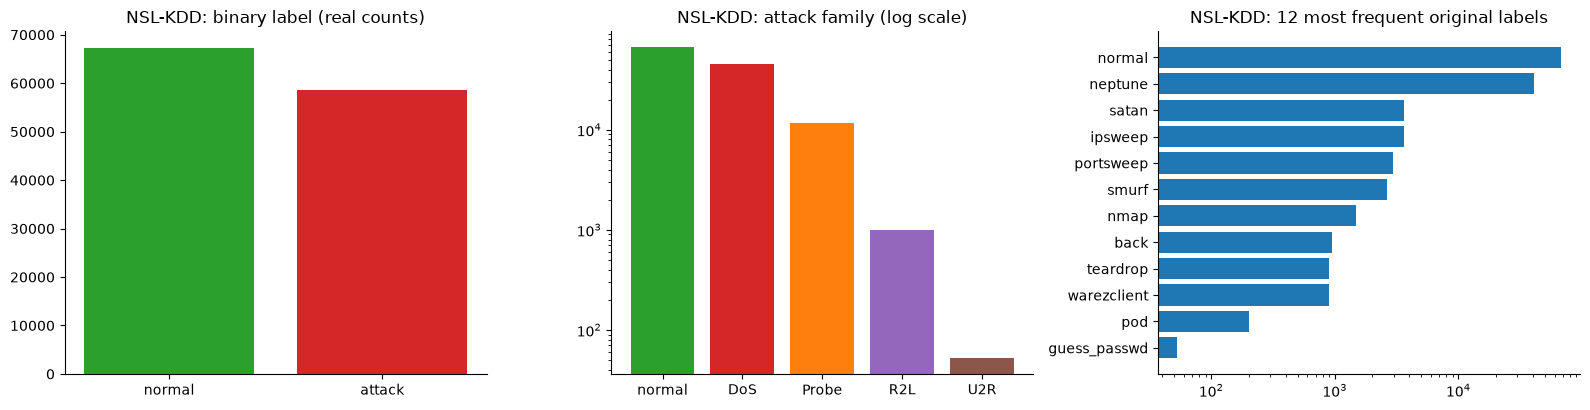

In [6]:
print("NSL-KDD  shape:", nsl.shape, "(41 features + label + difficulty + family)")
print("features (41):", NSL_FEATURES)
print("categorical  :", NSL_CATEGORICAL, "| distinct values:", {c: int(nsl[c].nunique()) for c in NSL_CATEGORICAL})
vc = nsl["label"].value_counts()
print("\noriginal label values (%d) and counts:" % len(vc)); print(vc.to_string())
print("\nfamily counts:", nsl["family"].value_counts().to_dict())
print("binary: normal =", int((nsl.label == "normal").sum()), "| attack =", int((nsl.label != "normal").sum()),
      "| attack rate = %.3f (paper test set: 0.46)" % (nsl.label != "normal").mean())

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
fc = nsl["family"].value_counts()
ax[0].bar(["normal", "attack"], [(nsl.label == "normal").sum(), (nsl.label != "normal").sum()], color=["tab:green", "tab:red"])
ax[0].set_title("NSL-KDD: binary label (real counts)")
ax[1].bar(fc.index, fc.values, color=["tab:green", "tab:red", "tab:orange", "tab:purple", "tab:brown"][:len(fc)]); ax[1].set_yscale("log")
ax[1].set_title("NSL-KDD: attack family (log scale)")
top = vc.head(12); ax[2].barh(top.index[::-1], top.values[::-1], color="tab:blue"); ax[2].set_xscale("log")
ax[2].set_title("NSL-KDD: 12 most frequent original labels")
plt.tight_layout(); plt.show()

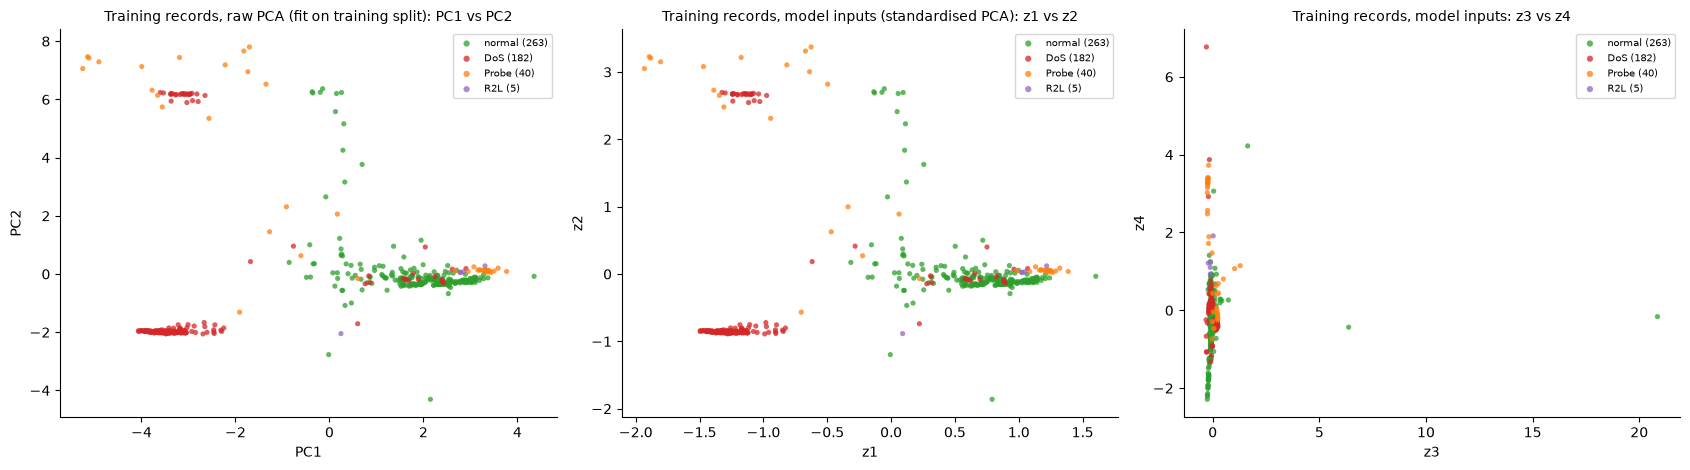

NSL-KDD training split of Table 2: (490, 4) | classes: {'DoS': np.int64(182), 'Probe': np.int64(40), 'R2L': np.int64(5), 'normal': np.int64(263)}


In [7]:
FAM_COL = {"normal": "tab:green", "DoS": "tab:red", "Probe": "tab:orange", "R2L": "tab:purple", "U2R": "black"}
def scatter_by(ax, A, labels, cols=None, title="", xl="", yl="", s=14):
    cats = sorted(set(labels), key=lambda c: (c != "normal", c))
    cmap = plt.get_cmap("tab10")
    for k, c in enumerate(cats):
        m = labels == c
        col = (cols or {}).get(c, cmap(k % 10))
        ax.scatter(A[m, 0], A[m, 1], s=s, alpha=0.75, color=col, label=f"{c} ({m.sum()})", edgecolor="none")
    ax.set_title(title, fontsize=10); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend(fontsize=7, markerscale=1.2)

d = D_T2
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
scatter_by(ax[0], d["Ptr"][:, [0, 1]], d["fam_tr"], FAM_COL, "Training records, raw PCA (fit on training split): PC1 vs PC2", "PC1", "PC2")
scatter_by(ax[1], d["Xtr"][:, [0, 1]], d["fam_tr"], FAM_COL, "Training records, model inputs (standardised PCA): z1 vs z2", "z1", "z2")
scatter_by(ax[2], d["Xtr"][:, [2, 3]], d["fam_tr"], FAM_COL, "Training records, model inputs: z3 vs z4", "z3", "z4")
plt.tight_layout(); plt.show()
print("NSL-KDD training split of Table 2:", d["Xtr"].shape, "| classes:", dict(zip(*np.unique(d["fam_tr"], return_counts=True))))

UNSW-NB15 shape: (82332, 45)
features (42): ['dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports']
label values: {1: 45332, 0: 37000} (0 = normal, 1 = attack)
attack_cat values and counts:
attack_cat
Normal            37000
Generic           18871
Exploits          11132
Fuzzers            6062
DoS                4089
Reconnaissance     3496
Analysis            677
Backdoor            583
Shellcode           378
Worms                44


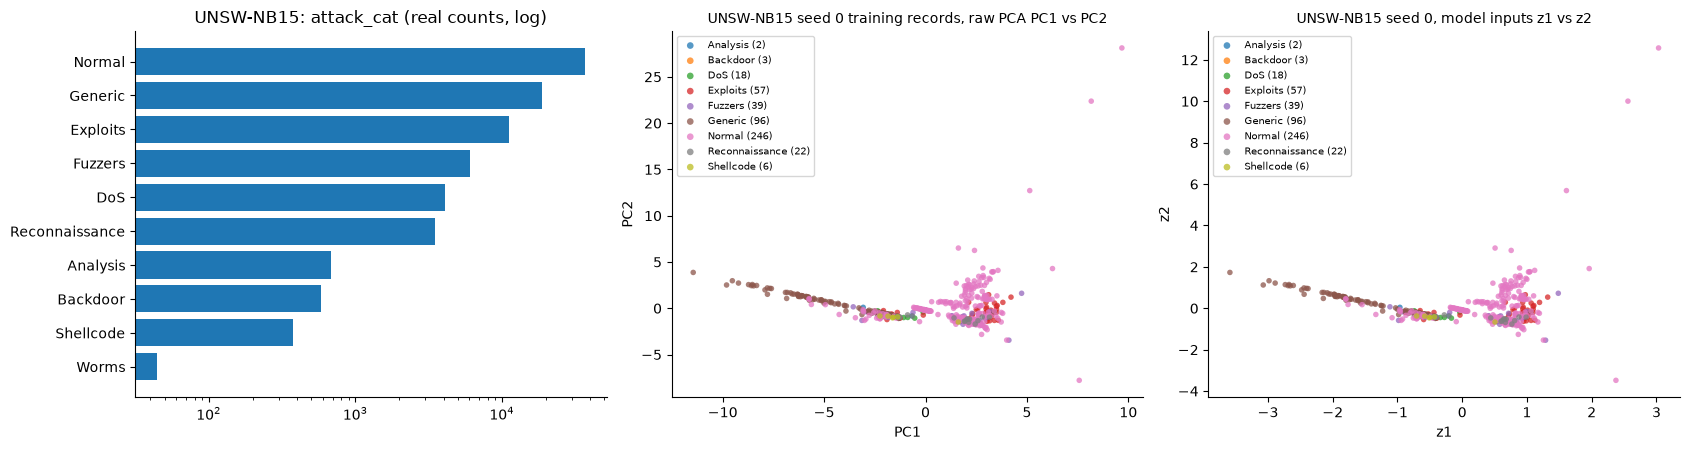

UNSW-NB15 seed-0 subsample: (489, 4) (211, 4) | attack rate train = 0.50


In [8]:
print("UNSW-NB15 shape:", unsw.shape)
unsw_feats = [c for c in unsw.columns if c not in UNSW_DROP]
print("features (%d):" % len(unsw_feats), unsw_feats)
print("label values:", unsw["label"].value_counts().to_dict(), "(0 = normal, 1 = attack)")
print("attack_cat values and counts:"); print(unsw["attack_cat"].value_counts().to_string())
D_U0 = prep_unsw(unsw, 700, 4, 0)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
ac = unsw["attack_cat"].value_counts()
ax[0].barh(ac.index[::-1], ac.values[::-1], color="tab:blue"); ax[0].set_xscale("log"); ax[0].set_title("UNSW-NB15: attack_cat (real counts, log)")
scatter_by(ax[1], D_U0["Ptr"][:, [0, 1]], D_U0["fam_tr"], None, "UNSW-NB15 seed 0 training records, raw PCA PC1 vs PC2", "PC1", "PC2", s=16)
scatter_by(ax[2], D_U0["Xtr"][:, [0, 1]], D_U0["fam_tr"], None, "UNSW-NB15 seed 0, model inputs z1 vs z2", "z1", "z2", s=16)
plt.tight_layout(); plt.show()
print("UNSW-NB15 seed-0 subsample:", D_U0["Xtr"].shape, D_U0["Xte"].shape, "| attack rate train = %.2f" % D_U0["ytr"].mean())

XOR benchmark (paper-defined, generated by design): X (400, 2) | labels {np.int64(0): np.int64(206), np.int64(1): np.int64(194)} | noise sd 0.15


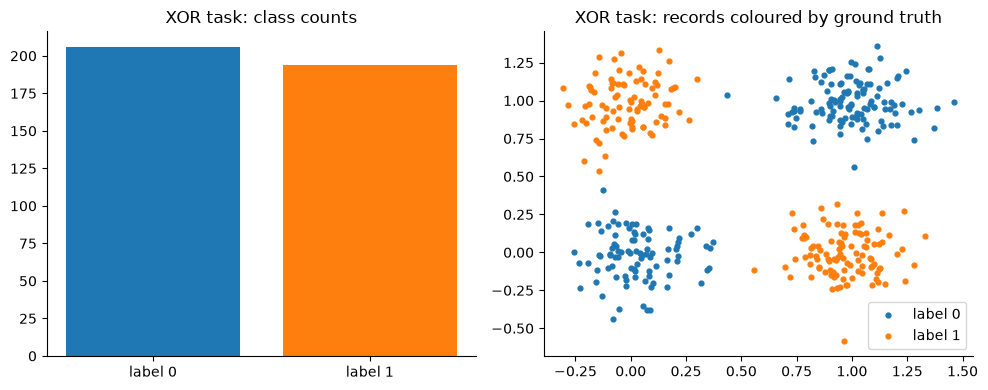

In [9]:
# The XOR task of the neutral-atom reservoir (Fig. 1) is defined by the paper itself: four Gaussian clusters at the corners of the unit square, label = XOR of the corner bits.
def make_xor(n_samples, noise, seed):
    rng = np.random.default_rng(seed)
    C = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], float); Lb = np.array([0, 1, 1, 0])
    idx = rng.integers(0, 4, n_samples)
    return C[idx] + noise * rng.standard_normal((n_samples, 2)), Lb[idx], idx
Xx, yx, cx = make_xor(400, 0.15, 0)
print("XOR benchmark (paper-defined, generated by design): X", Xx.shape, "| labels", dict(zip(*np.unique(yx, return_counts=True))), "| noise sd 0.15")
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].bar(["label 0", "label 1"], np.bincount(yx), color=["tab:blue", "tab:orange"]); ax[0].set_title("XOR task: class counts")
for lab, col in [(0, "tab:blue"), (1, "tab:orange")]:
    ax[1].scatter(Xx[yx == lab, 0], Xx[yx == lab, 1], s=12, color=col, label=f"label {lab}")
ax[1].set_title("XOR task: records coloured by ground truth"); ax[1].legend(); plt.tight_layout(); plt.show()

## 4. The SQNN simulator

The authors simulate the density matrix with PennyLane's `default.mixed` (a $16\times16$ matrix per sample). In our test (a loaded 8-core Windows PC) one
forward pass for a batch of 490 records took about 12 s there, which is why the paper's 30-seed study took hours. Here is an equivalent but much faster exact simulator.

**Idea: the Pauli transfer matrix.** Write the state as $\rho=\frac1{16}\sum_a r_a\,\sigma_a$ with $a\in\{I,X,Y,Z\}^4$ and $r_a=\mathrm{Tr}(\rho\,\sigma_a)$ (the paper's Eq. 1).
Then every operation is a *real* linear map on the 256-vector $r$:

* $R_Z(\varphi)R_Y(\theta)$ on qubit $i$ rotates the Bloch vector $(r_X,r_Y,r_Z)$ of that qubit and leaves $r_I$ alone (a $4\times4$ matrix per record);
* the CNOT ring is one fixed signed permutation of the 256 entries (computed once from the real $16\times16$ CNOT unitaries);
* the depolarising channel multiplies each entry by $\eta^{w}$ with $\eta=1-4\gamma/3$ and $w$ the weight of the Pauli string
  (this is the paper's Theorem 1 for one layer, derived below for one qubit), the dephasing channel multiplies by $\sqrt{1-\gamma}^{\,\#\{X,Y\}}$;
* the read-out is the single entry $r_{Z_0 I I I}=\langle Z_0\rangle$.

Everything is written with `autograd`, so exact gradients with respect to weights *and inputs* (needed for FGSM/PGD) come for free.
The code also runs *M independent models side by side* (a leading batch axis for weights, data, channel strength and dropout masks) so that, for example, the seeds of one experiment are trained in one call; models in a batch never interact, which is why `SQNN` with `M = 1` is the ordinary case.
Correctness is not taken on trust: the cell at the end asserts that the result equals PennyLane's `default.mixed` to 1e-9.

In [10]:
Q = N_QUBITS
I2 = np.eye(2, dtype=complex); X2 = np.array([[0, 1], [1, 0]], complex); Y2 = np.array([[0, -1j], [1j, 0]]); Z2 = np.diag([1., -1.]).astype(complex)
PAULI = [I2, X2, Y2, Z2]
def kron_all(ms):
    out = np.array([[1.0 + 0j]])
    for m in ms: out = np.kron(out, m)
    return out
STRINGS = list(itertools.product(range(4), repeat=Q))
PM = np.stack([kron_all([PAULI[i] for i in s]) for s in STRINGS])            # (256, 16, 16), wire 0 = most significant qubit (PennyLane convention)
def cnot_ring_unitary(n=Q):
    U = np.eye(2 ** n, dtype=complex)
    for c, t in [(i, (i + 1) % n) for i in range(n)]:                          # CNOT(0,1), CNOT(1,2), CNOT(2,3), CNOT(3,0) in this order
        P = np.zeros((2 ** n, 2 ** n))
        for b in range(2 ** n):
            bits = [(b >> (n - 1 - k)) & 1 for k in range(n)]
            if bits[c]: bits[t] ^= 1
            P[sum(v << (n - 1 - k) for k, v in enumerate(bits)), b] = 1
        U = P @ U
    return U
U_RING = cnot_ring_unitary()
PTM_RING = np.einsum("bij,aji->ba", PM, np.einsum("ij,ajk,lk->ail", U_RING, PM, U_RING.conj())).real / 16   # r' = PTM r
WEIGHT = np.array([sum(v != 0 for v in s) for s in STRINGS])                  # Pauli weight of every string
N_XY = np.array([sum(v in (1, 2) for v in s) for s in STRINGS])
b0 = np.array([1., 0, 0, 1])
R_INIT = np.einsum("a,b,c,d->abcd", b0, b0, b0, b0)                           # |0000><0000|: r_a = 1 for strings made of I and Z only
print("PTM of the CNOT ring is a signed permutation:", bool(np.all(np.abs(PTM_RING).sum(0) == 1)), "| entries in", sorted(set(np.unique(PTM_RING))))

def channel_diag(gamma, noise):
    """Diagonal of the channel in the Pauli basis, shape (256, M) for a vector of M strengths."""
    gamma = np.atleast_1d(np.asarray(gamma, float))
    if noise == "depol": return (1 - 4 * gamma[None, :] / 3) ** WEIGHT[:, None]          # PennyLane DepolarizingChannel(gamma)
    if noise == "phase": return (1 - gamma[None, :]) ** (0.5 * N_XY[:, None])            # PennyLane PhaseDamping(gamma)
    raise ValueError(noise)

def expval_z0_batch(x, w_in, w_rot, mask, gamma, noise="depol"):
    """<Z_0> after L layers for M independent models at once.
    x (M, N, d); w_in (M, L, Q); w_rot (M, L, Q, 2); mask (M, L, Q, 2) multiplies the trainable rotations; gamma (M,) channel strengths.
    Returns (M, N). The state is the Pauli vector r with shape (256, M, N); one qubit rotation mixes the 3 non-identity components."""
    M, N = x.shape[0], x.shape[1]; L = w_in.shape[1]
    r = anp.tile(anp.array(R_INIT).reshape(256, 1, 1), (1, M, N))
    gam = np.broadcast_to(np.asarray(gamma, float), (M,))
    D = channel_diag(gam, noise).reshape(256, M, 1) if np.any(gam > 0) else None
    for l in range(L):
        for i in range(Q):
            th = w_in[:, l, i][:, None] * x[:, :, i % x.shape[2]] + (mask[:, l, i, 0] * w_rot[:, l, i, 0])[:, None]   # RY: data re-uploading + trainable angle (M, N)
            ph = (mask[:, l, i, 1] * w_rot[:, l, i, 1])[:, None] * anp.ones_like(th)                                  # RZ angle (M, N)
            c, s, cp, sp = anp.cos(th), anp.sin(th), anp.cos(ph), anp.sin(ph)
            rows = [[cp * c, -sp, cp * s], [sp * c, cp, sp * s], [-s, None, c]]       # Bloch rotation of R_Z(phi) R_Y(theta)
            rr = anp.reshape(r, (4 ** i, 4, 4 ** (Q - 1 - i), M, N))
            comp = [rr[:, 1], rr[:, 2], rr[:, 3]]
            new = [rr[:, 0]]                                                           # the identity component never changes
            for a_ in range(3):
                acc = None
                for m_ in range(3):
                    if rows[a_][m_] is None: continue
                    t_ = rows[a_][m_] * comp[m_]
                    acc = t_ if acc is None else acc + t_
                new.append(acc)
            r = anp.reshape(anp.stack(new, axis=1), (256, M, N))
        r = anp.tensordot(PTM_RING, r, axes=1)                                         # CNOT ring: one fixed 256 x 256 map
        if D is not None: r = r * D                                                    # depolarising / dephasing on every qubit
    return r[3 * 64]                                                                   # <Z_0> = r[Z,I,I,I]

def expval_z0(x, w_in, w_rot, mask, gamma, noise="depol"):
    """Single-model convenience wrapper: x (B, d), w_in (L, Q), w_rot (L, Q, 2), mask (L, Q, 2); returns (B,)."""
    return expval_z0_batch(x[None], w_in[None], w_rot[None], mask[None], gamma, noise)[0]

PTM of the CNOT ring is a signed permutation: True | entries in [np.float64(-1.0), np.float64(0.0), np.float64(1.0)]


### Cross-check against PennyLane's density-matrix device

The next cell defines the authors' circuit as a real PennyLane QNode on `default.mixed` (it is also the circuit drawn in Section 5)
and asserts that the fast simulator gives the same $\langle Z_0\rangle$ for random inputs and weights, for depolarising noise, dephasing noise, no noise,
and a dropout mask, at depth 3 and 5.

In [11]:
dev = qml.device("default.mixed", wires=Q)
@qml.qnode(dev, interface="autograd", diff_method="backprop")
def sqnn_qnode(x, w_in, w_rot, mask, p, noise="depol"):
    for l in range(w_in.shape[0]):
        for i in range(Q):
            feat = x[..., i % x.shape[-1]]
            qml.RY(w_in[l, i] * feat + mask[l, i, 0] * w_rot[l, i, 0], wires=i)
            qml.RZ(mask[l, i, 1] * w_rot[l, i, 1], wires=i)
        for i in range(Q):
            qml.CNOT(wires=[i, (i + 1) % Q])
        if p > 0:
            for i in range(Q):
                (qml.DepolarizingChannel if noise == "depol" else qml.PhaseDamping)(p, wires=i)
    return qml.expval(qml.PauliZ(0))

rg = np.random.default_rng(SEED)
worst = 0.0
for L, noise, p, use_mask in [(3, "depol", 0.30, False), (3, "depol", 0.05, True), (3, "phase", 0.40, False), (3, "depol", 0.0, False), (5, "depol", 0.15, True)]:
    x = rg.normal(size=(6, 4)); w_in = rg.normal(size=(L, Q)); w_rot = rg.normal(0, 0.5, (L, Q, 2))
    mask = (rg.random((L, Q, 2)) > 0.4).astype(float) if use_mask else np.ones((L, Q, 2))
    a = expval_z0(x, w_in, w_rot, mask, p, noise); b = np.array(sqnn_qnode(x, w_in, w_rot, mask, p, noise))
    worst = max(worst, float(np.abs(a - b).max()))
    print(f"L={L} noise={noise:5s} gamma={p:.2f} mask={use_mask!s:5s} max |fast - PennyLane| = {np.abs(a - b).max():.2e}")
assert worst < 1e-9, worst
print("Equivalence assertion passed: the fast simulator reproduces PennyLane default.mixed (worst error %.1e)." % worst)

L=3 noise=depol gamma=0.30 mask=False max |fast - PennyLane| = 4.12e-15


L=3 noise=depol gamma=0.05 mask=True  max |fast - PennyLane| = 1.09e-13


L=3 noise=phase gamma=0.40 mask=False max |fast - PennyLane| = 4.80e-14


L=3 noise=depol gamma=0.00 mask=False max |fast - PennyLane| = 1.80e-16


L=5 noise=depol gamma=0.15 mask=True  max |fast - PennyLane| = 1.16e-14
Equivalence assertion passed: the fast simulator reproduces PennyLane default.mixed (worst error 1.1e-13).


## Quantum Circuit Architecture

The circuit that the paper trains is drawn below from the real PennyLane QNode of Section 4 (`qml.draw_mpl`); the cell above has asserted that the
training engine computes exactly the same function. Three distinct architectures occur in the paper:

1. **SQNN, depth 3, depolarising $\gamma$** (Tables 2-4; with $\gamma=0$ the same circuit without the channel is the noiseless VQC);
2. **SQNN with per-gate quantum dropout** (Table 5): the same gates, but each trainable rotation angle $\theta_{l,i,k}$ is multiplied by a Bernoulli mask drawn afresh at every training step
   (`mask = 0` gives the identity). The data-encoding term $w_{in}x_i$ is never masked. A masked instance is drawn;
3. **SQNN, depth 5** (Sec. 8.5), same structure with five layers.

Assumptions where the PDF is silent (all taken from the public code): each layer is `RY(w_in*x_i + theta_1)` followed by `RZ(theta_2)` per qubit; the ring is
`CNOT(0,1), CNOT(1,2), CNOT(2,3), CNOT(3,0)`; the channel acts after the ring; with $d=4$ features and 4 qubits, qubit $i$ receives feature $i$;
initial state $|0000\rangle$; read-out $\langle Z_0\rangle$ then the classical logistic head $\sigma(a\langle Z_0\rangle+b)$ with two more trainable numbers. Shots are not used (exact expectation).

Architecture 1: SQNN L=3, depolarising gamma=0.30: qubits = 4 | depth = 21 | gates = 48 | trainable circuit parameters = 36 (w_in 12, rotations 24) + head (a, b) = 38 trainable numbers


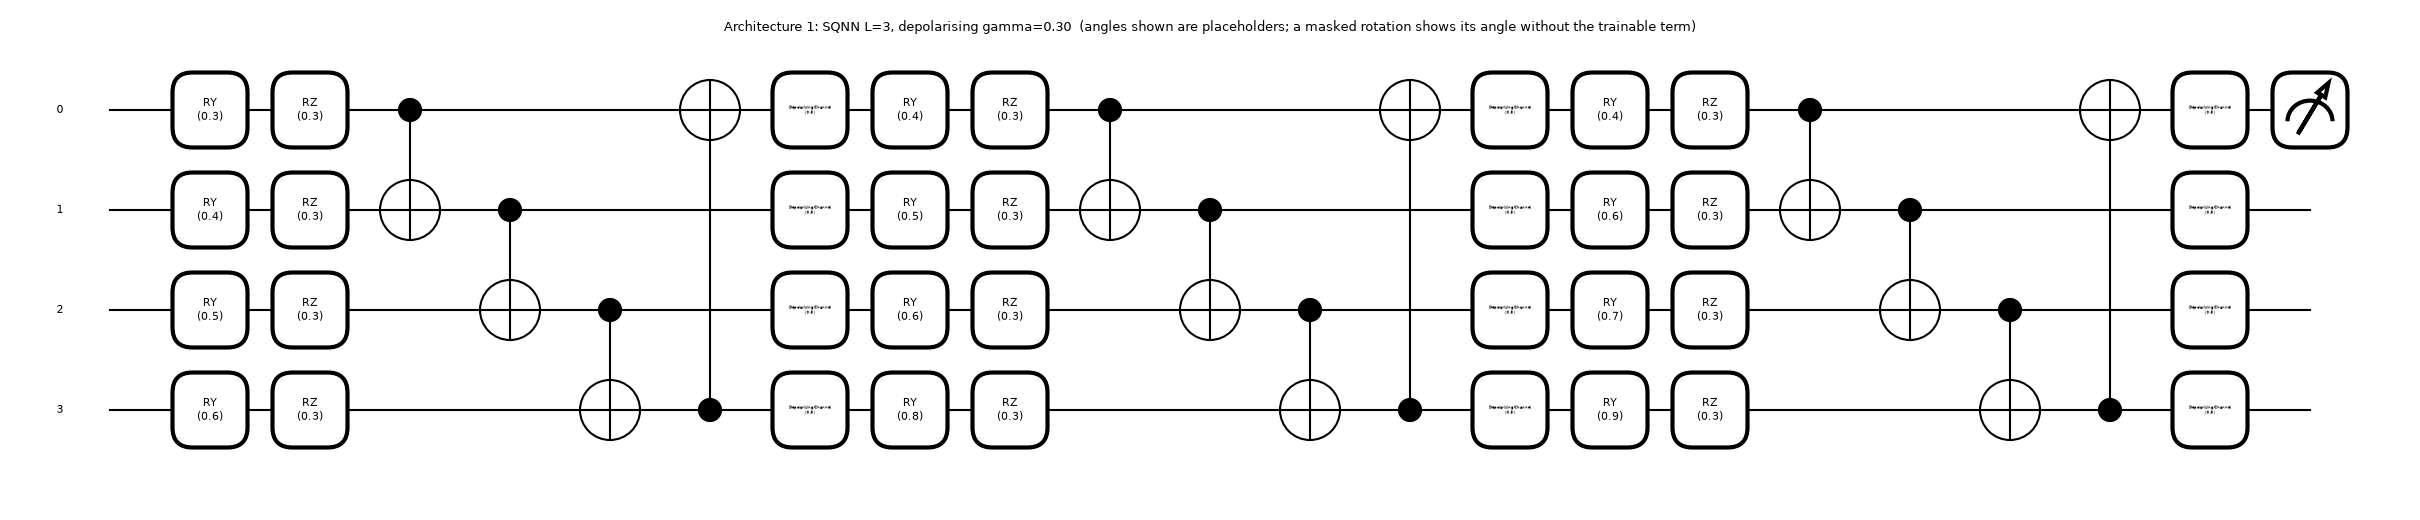

Architecture 2: SQNN L=3 with a dropout mask (p=0.3), no channel: qubits = 4 | depth = 18 | gates = 36 | trainable circuit parameters = 36 (w_in 12, rotations 24) + head (a, b) = 38 trainable numbers


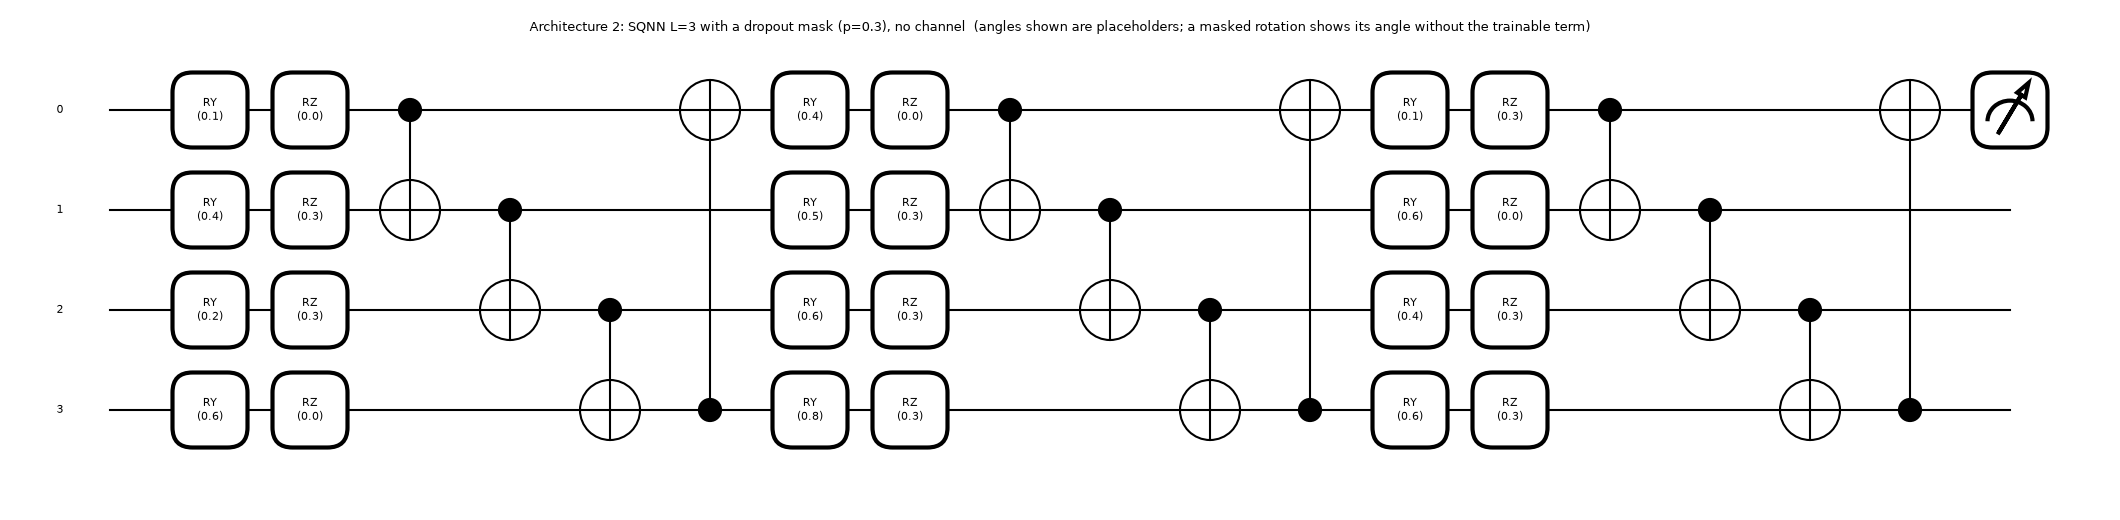

Architecture 3: SQNN L=5, depolarising gamma=0.05: qubits = 4 | depth = 35 | gates = 80 | trainable circuit parameters = 60 (w_in 20, rotations 40) + head (a, b) = 62 trainable numbers


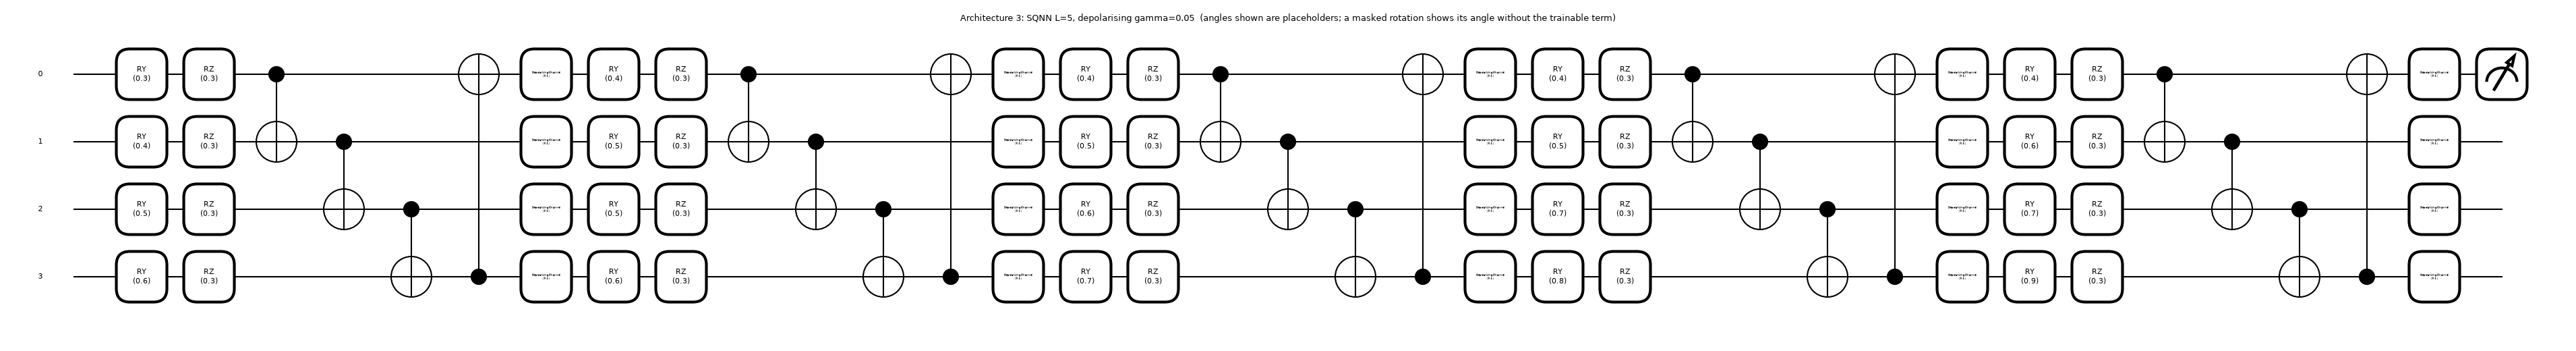

In [12]:
def circuit_report(L, name, gamma, mask=None):
    w_in = np.zeros((L, Q)); w_rot = np.zeros((L, Q, 2)); x = np.zeros(4)
    m = np.ones((L, Q, 2)) if mask is None else mask
    tape = qml.workflow.construct_batch(sqnn_qnode, level="device")(x, w_in, w_rot, m, gamma)[0][0]
    n_train = L * Q + L * Q * 2 + 2
    print(f"{name}: qubits = {Q} | depth = {tape.graph.get_depth()} | gates = {len(tape.operations)} | "
          f"trainable circuit parameters = {L*Q + L*Q*2} (w_in {L*Q}, rotations {L*Q*2}) + head (a, b) = {n_train} trainable numbers")

rg2 = np.random.default_rng(3)
mask_example = (rg2.random((3, Q, 2)) > 0.3).astype(float)
for L, name, gam, mk, fn in [(3, "Architecture 1: SQNN L=3, depolarising gamma=0.30", 0.30, None, "arch1"),
                             (3, "Architecture 2: SQNN L=3 with a dropout mask (p=0.3), no channel", 0.0, mask_example, "arch2"),
                             (5, "Architecture 3: SQNN L=5, depolarising gamma=0.05", 0.05, None, "arch3")]:
    circuit_report(L, name, gam, mk)
    w_in = np.array(np.linspace(0.5, 1.5, L * Q).reshape(L, Q)); w_rot = np.full((L, Q, 2), 0.3)
    mk_ = np.ones((L, Q, 2)) if mk is None else mk
    fig, ax = qml.draw_mpl(sqnn_qnode, decimals=1, fontsize=8)(np.array([0.1, 0.2, 0.3, 0.4]), w_in, w_rot, mk_, gam)
    fig.suptitle(name + "  (angles shown are placeholders; a masked rotation shows its angle without the trainable term)", fontsize=9)
    plt.show()

## 6. Training, attacks and baselines

`SQNN` holds the weights as one flat vector (`w_in` $L\times4$, `w_rot` $L\times4\times2$, then $a$, $b$). `fit` runs full-batch Adam
(PennyLane's update rule) on the binary cross-entropy of $\sigma(a\langle Z_0\rangle + b)$. Per-gate dropout draws a fresh mask for the
trainable rotations at every step and is switched off at inference (mask = 1). The depolarising channel is on in training *and* inference
as in the paper. `gamma` can be overridden at inference to test whether a channel applied only at inference helps.

Attacks (all white-box, exact gradient of the cross-entropy with respect to the input):
FGSM $x+\varepsilon\,\mathrm{sign}(\nabla_x\mathcal L)$; PGD-$\ell_\infty$ with random start, step $\varepsilon/4$, projection on the $\varepsilon$-ball;
PGD-$\ell_2$ with normalised steps $\varepsilon_2/4$ and projection on the $\ell_2$ ball. Robust accuracy is the accuracy on the adversarial
test records.

In [13]:
def _bce_rows(p, y):
    p = anp.clip(p, 1e-7, 1 - 1e-7)
    return -anp.mean(y * anp.log(p) + (1 - y) * anp.log(1 - p), axis=1)           # one value per model

class SQNN:
    """A batch of M independent SQNNs (M = 1 is the ordinary case). gamma, p_drop and seed may be scalars or length-M lists.
    Models in a batch never interact: each has its own weights, data, mask stream and channel strength; batching only saves Python overhead."""
    def __init__(self, n_layers=3, gamma=0.0, p_drop=0.0, noise="depol", seed=0):
        g, pdr, sd = (np.atleast_1d(np.asarray(v, float)) for v in (gamma, p_drop, seed))
        self.M = max(len(g), len(pdr), len(sd)); M = self.M
        self.L, self.noise = n_layers, noise
        self.gamma, self.p_drop, seeds = (np.broadcast_to(v, (M,)).copy() for v in (g, pdr, sd))
        self.rngs = [np.random.default_rng(int(s)) for s in seeds]
        th = []
        for rng in self.rngs:                                                # same draw order as the authors' code
            w_in = rng.normal(0, 1.0, (n_layers, Q)); w_rot = rng.normal(0, 0.3, (n_layers, Q, 2))
            th.append(np.concatenate([w_in.ravel(), w_rot.ravel(), [2.0, 0.0]]))
        self.theta = np.stack(th)                                            # (M, P)
        self.ones = np.ones((M, n_layers, Q, 2))
    def unpack(self, th):
        n1, n2 = self.L * Q, self.L * Q * 3
        return (anp.reshape(th[:, :n1], (self.M, self.L, Q)), anp.reshape(th[:, n1:n2], (self.M, self.L, Q, 2)), th[:, n2], th[:, n2 + 1])
    def _xy(self, X, y=None):
        X = np.asarray(X, float)
        if X.ndim == 2: X = np.broadcast_to(X, (self.M,) + X.shape).copy()
        if y is None: return X
        y = np.asarray(y, float)
        if y.ndim == 1: y = np.broadcast_to(y, (self.M,) + y.shape).copy()
        return X, y
    def _gam(self, gamma): return self.gamma if gamma is None else np.broadcast_to(np.asarray(gamma, float), (self.M,))
    def proba_th(self, th, X, mask, gamma):
        w_in, w_rot, a, b = self.unpack(th)
        z = expval_z0_batch(X, w_in, w_rot, mask, gamma, self.noise)
        return 1.0 / (1.0 + anp.exp(-(a[:, None] * z + b[:, None])))
    def loss_th(self, th, X, y, mask, gamma):
        return anp.sum(_bce_rows(self.proba_th(th, X, mask, gamma), y))      # sum over independent models -> per-model gradients
    def fit(self, X, y, epochs=45, lr=LR, b1=0.9, b2=0.999, eps=1e-8):
        X, y = self._xy(X, y)
        gfn = grad(self.loss_th); th = self.theta.copy(); m = np.zeros_like(th); v = np.zeros_like(th)
        for t in range(1, epochs + 1):
            mask = np.stack([(r.random((self.L, Q, 2)) > pd).astype(float) if pd > 0 else np.ones((self.L, Q, 2))
                             for r, pd in zip(self.rngs, self.p_drop)])      # fresh per-gate Bernoulli mask per step (only where p_drop > 0)
            g = gfn(th, X, y, mask, self.gamma)
            m = b1 * m + (1 - b1) * g; v = b2 * v + (1 - b2) * g * g
            th = th - lr * np.sqrt(1 - b2 ** t) / (1 - b1 ** t) * m / (np.sqrt(v) + eps)      # Adam (PennyLane's update rule)
        self.theta = th
        return self
    def proba(self, X, gamma=None):
        p = np.asarray(self.proba_th(self.theta, self._xy(X), self.ones, self._gam(gamma)))
        return p[0] if self.M == 1 else p
    def predict(self, X, gamma=None):
        return (self.proba(X, gamma) >= 0.5).astype(int)
    def acc(self, X, y, gamma=None):
        yy = np.asarray(y)
        if self.M == 1: return float((self.predict(X, gamma) == yy.reshape(-1)).mean())
        return (self.predict(X, gamma) == (yy if yy.ndim == 2 else yy[None, :])).mean(axis=-1)
    def input_grad(self, X, y, gamma=None):
        X, y = self._xy(X, y); g = self._gam(gamma)
        out = grad(lambda Xv: self.loss_th(self.theta, Xv, y, self.ones, g))(X)
        return out[0] if self.M == 1 else out

def fgsm(model, X, y, eps, gamma=None):
    return X + eps * np.sign(model.input_grad(X, y, gamma))

def pgd_linf(model, X, y, eps, steps, rng, gamma=None):
    Xa = X + rng.uniform(-eps, eps, X.shape)
    for _ in range(steps):
        Xa = np.clip(Xa + (eps / 4) * np.sign(model.input_grad(Xa, y, gamma)), X - eps, X + eps)
    return Xa

def pgd_l2(model, X, y, eps2, steps, rng, gamma=None):
    d0 = rng.normal(size=X.shape); d0 /= np.linalg.norm(d0, axis=-1, keepdims=True) + 1e-12
    Xa = X + rng.uniform(0, eps2, X.shape[:-1] + (1,)) * d0
    for _ in range(steps):
        g = model.input_grad(Xa, y, gamma); g /= np.linalg.norm(g, axis=-1, keepdims=True) + 1e-12
        Xa = Xa + (eps2 / 4) * g
        de = Xa - X; nm = np.linalg.norm(de, axis=-1, keepdims=True)
        Xa = X + de * np.minimum(1.0, eps2 / (nm + 1e-12))
    return Xa

def tile_models(model, X):
    """Give every model of a batch its own copy of a shared array X of shape (N, d) -> (M, N, d)."""
    return np.broadcast_to(X, (model.M,) + X.shape).copy() if model.M > 1 else X

def chunks(seq, size):
    seq = list(seq); return [seq[i:i + size] for i in range(0, len(seq), max(1, size))]
CAP = 1600     # CHOICE: at most about 1600 (models x records) per batch, to keep memory below about 0.5 GB

# quick smoke test on the Table-2 data: train a noiseless and a gamma=0.3 SQNN (20 epochs) in one batch (M = 2)
t0 = time.time()
m_ = SQNN(3, gamma=[0.0, 0.3], seed=0).fit(D_T2["Xtr"], D_T2["ytr"], epochs=20)
for g, tr, te in zip(m_.gamma, m_.acc(D_T2["Xtr"], D_T2["ytr"]), m_.acc(D_T2["Xte"], D_T2["yte"])):
    print(f"gamma={g:.2f}: train acc {tr:.3f} | test acc {te:.3f}")
print("two fits of 20 epochs (one batch) took %.1f s" % (time.time() - t0))

gamma=0.00: train acc 0.896 | test acc 0.833
gamma=0.30: train acc 0.537 | test acc 0.538
two fits of 20 epochs (one batch) took 14.4 s


## 7. The theorem and Proposition 1, tested numerically

**Theorem 1 (decoherence contraction).** For one qubit, $\Lambda_\gamma(\rho)=(1-\gamma)\rho+\frac\gamma3\sum_{a}\sigma_a\rho\sigma_a$ gives
$\langle\sigma_a\rangle\mapsto(1-\gamma-\gamma/3)\langle\sigma_a\rangle=\eta\langle\sigma_a\rangle$ for $a\in\{x,y,z\}$ because $\sum_b\sigma_b\sigma_a\sigma_b=-\sigma_a$ (sum over all three Paulis,
including $b=a$) and $\langle I\rangle$ is untouched; a weight-$w$ string is touched by $w$ channels per layer, hence $\eta^{wL}$.

**Test (a), the theorem as stated.** Take a random 3-qubit mixed state, apply $\Lambda_\gamma$ on every qubit $L$ times (no gates in between), and compare all 64 Pauli
expectations with $\eta^{wL}$ times the initial ones. This must agree to machine precision.

**Test (b), the circuit.** In the SQNN the layers are *not* identity: CNOTs map Pauli strings of one weight to strings of another weight
($Z_0\to Z_0Z_3$ for the last CNOT of the ring), so the factor for the read-out $\langle Z_0\rangle$ is not simply $\eta^L$. The paper's argument
writes $\langle O\rangle_\gamma=\eta^L\langle O\rangle_0+c$. We measure how far that is from the truth for the real circuit:
over 300 random inputs and random weights, regress $\langle Z_0\rangle_\gamma$ on $\langle Z_0\rangle_0$ (slope, $R^2$) and compare the input-gradient norms
$\|\nabla_x\langle Z_0\rangle_\gamma\|/\|\nabla_x\langle Z_0\rangle_0\|$ with $\eta^L$ (Proposition 1).

Test (a): max |r_a(L) - eta^(wL) r_a(0)| over all 64 Pauli strings, 9 settings: 9.99e-16
   eta^L at L=3: gamma=0.15 -> 0.512 (paper 0.512), gamma=0.30 -> 0.216 (paper 0.216)


          effective exponent: slope = eta^k with k = 6.9 (the paper's statement corresponds to k = L = 3)
Test (b): <Z0>_gamma = slope * <Z0>_0 + intercept: slope = 0.029, intercept = 0.000, R^2 = 0.879   (eta^L = 0.216)
          input-gradient norm ratio: median 0.028, 10-90% range [0.022, 0.049]   (eta^L = 0.216, eta = 0.600)


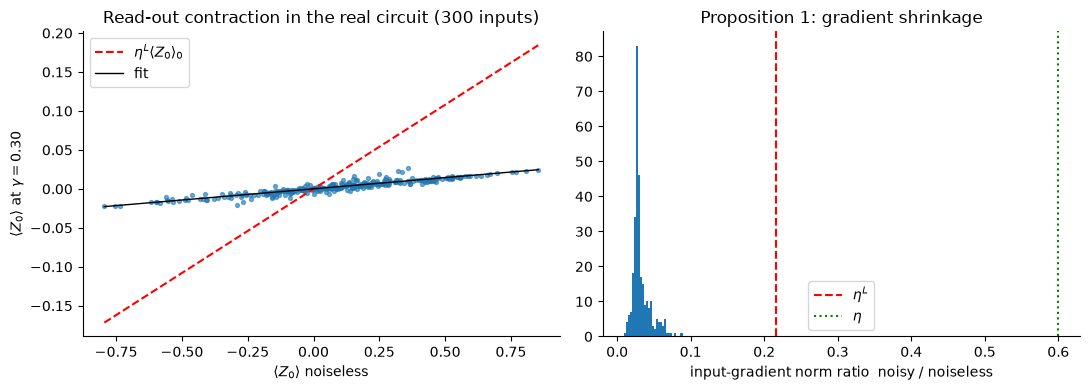

In [14]:
def depolarise_all(rho, gamma, n):
    out = rho.copy()
    for j in range(n):
        acc = (1 - gamma) * out
        for P in (X2, Y2, Z2):
            K = kron_all([P if k == j else I2 for k in range(n)])
            acc = acc + (gamma / 3) * K @ out @ K.conj().T
        out = acc
    return out

n3 = 3
strings3 = list(itertools.product(range(4), repeat=n3)); P3 = np.stack([kron_all([PAULI[i] for i in s]) for s in strings3]); w3 = np.array([sum(v != 0 for v in s) for s in strings3])
rr = np.random.default_rng(SEED); A = rr.normal(size=(8, 8)) + 1j * rr.normal(size=(8, 8)); rho0 = A @ A.conj().T; rho0 /= np.trace(rho0).real
r0_ = np.einsum("aij,ji->a", P3, rho0).real
rows, worst_a = [], 0.0
for gam in [0.05, 0.15, 0.30]:
    for Lc in [1, 3, 5]:
        rho = rho0.copy()
        for _ in range(Lc): rho = depolarise_all(rho, gam, n3)
        rL = np.einsum("aij,ji->a", P3, rho).real
        err = np.abs(rL - (1 - 4 * gam / 3) ** (w3 * Lc) * r0_).max(); worst_a = max(worst_a, err)
        rows.append((gam, Lc, err))
print("Test (a): max |r_a(L) - eta^(wL) r_a(0)| over all 64 Pauli strings, 9 settings: %.2e" % worst_a)
assert worst_a < 1e-12
RES["thm1_exact_err"] = worst_a
print("   eta^L at L=3: gamma=0.15 -> %.3f (paper 0.512), gamma=0.30 -> %.3f (paper 0.216)" % ((1 - 4 * .15 / 3) ** 3, (1 - 4 * .30 / 3) ** 3))

# Test (b): the real circuit
rb = np.random.default_rng(SEED + 1); Lc = 3; gam = 0.30
Xr = rb.normal(size=(300, 4)); w_in = rb.normal(size=(Lc, Q)); w_rot = rb.normal(0, 0.3, (Lc, Q, 2)); one = np.ones((Lc, Q, 2))
z0 = expval_z0(Xr, w_in, w_rot, one, 0.0); zg = expval_z0(Xr, w_in, w_rot, one, gam)
slope, icpt, rv, _, _ = stats.linregress(z0, zg)
gx = lambda g: grad(lambda Xv: anp.sum(expval_z0(Xv, w_in, w_rot, one, g)))(Xr)
ratio = np.linalg.norm(gx(gam), axis=1) / np.linalg.norm(gx(0.0), axis=1)
eta_L = (1 - 4 * gam / 3) ** Lc
eff_exp = np.log(max(slope, 1e-9)) / np.log(1 - 4 * gam / 3)
print("          effective exponent: slope = eta^k with k = %.1f (the paper's statement corresponds to k = L = 3)" % eff_exp)
print("Test (b): <Z0>_gamma = slope * <Z0>_0 + intercept: slope = %.3f, intercept = %.3f, R^2 = %.3f   (eta^L = %.3f)" % (slope, icpt, rv ** 2, eta_L))
print("          input-gradient norm ratio: median %.3f, 10-90%% range [%.3f, %.3f]   (eta^L = %.3f, eta = %.3f)" %
      (np.median(ratio), *np.percentile(ratio, [10, 90]), eta_L, 1 - 4 * gam / 3))
RES.update(slope=slope, r2=rv ** 2, grad_ratio=float(np.median(ratio)), eta_L=eta_L)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(z0, zg, s=8, alpha=0.6); xs = np.linspace(z0.min(), z0.max(), 5)
ax[0].plot(xs, eta_L * xs, "r--", label=r"$\eta^L\langle Z_0\rangle_0$"); ax[0].plot(xs, slope * xs + icpt, "k-", lw=1, label="fit")
ax[0].set_xlabel(r"$\langle Z_0\rangle$ noiseless"); ax[0].set_ylabel(r"$\langle Z_0\rangle$ at $\gamma=0.30$"); ax[0].legend(); ax[0].set_title("Read-out contraction in the real circuit (300 inputs)")
ax[1].hist(ratio, bins=30, color="tab:blue"); ax[1].axvline(eta_L, color="r", ls="--", label=r"$\eta^L$"); ax[1].axvline(1 - 4 * gam / 3, color="g", ls=":", label=r"$\eta$")
ax[1].set_xlabel("input-gradient norm ratio  noisy / noiseless"); ax[1].legend(); ax[1].set_title("Proposition 1: gradient shrinkage")
plt.tight_layout(); plt.show()

## 8. Adversarial robustness, single seed (Table 2 and Fig. 2)

Protocol of the authors' `run_adv.py`: 700 NSL-KDD records (490 train / 210 test, data seed 42), SQNN with $\gamma\in\{0,0.05,0.15,0.30\}$ trained for 55 epochs,
then clean accuracy and accuracy under FGSM ($\varepsilon=0.1,0.3$) and 5-step PGD ($\varepsilon=0.1,0.3$) with exact gradients. The classical models (RF, MLP, RBF-SVM)
are trained on the same four features and attacked by **transfer** from a logistic surrogate (FGSM only), exactly as the paper describes; this is weaker than a white-box attack.
The first table below is the paper's protocol (seed 0). Because the paper itself says one seed is unreliable, the same study is repeated for several seeds (data seed $42+k$, model seed $k$).

In [15]:
def classical_rows(D, seed, eps_list):
    surr = LogisticRegression(max_iter=2000).fit(D["Xtr"], D["ytr"]); w = surr.coef_.ravel()
    out = {}
    for name, clf in {"Random forest": RandomForestClassifier(n_estimators=200, random_state=seed),
                      "MLP": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=800, random_state=seed),
                      "RBF-SVM": SVC(kernel="rbf")}.items():
        clf.fit(D["Xtr"], D["ytr"])
        rec = {"clean": accuracy_score(D["yte"], clf.predict(D["Xte"]))}
        for e in eps_list:
            Xa = D["Xte"] - e * (2 * D["yte"] - 1)[:, None] * np.sign(w)[None, :]        # transfer FGSM from the logistic surrogate
            rec[f"fgsm@{e}"] = accuracy_score(D["yte"], clf.predict(Xa))
        out[name] = rec
    return out

T2 = {}      # (data seed k) -> {model name: {clean, fgsm@0.1, fgsm@0.3, pgd@0.1, pgd@0.3}} ; curves
t0 = time.time()
T2_NAMES = [f"SQNN gamma={g:.2f}" if g > 0 else "SQNN gamma=0 (VQC)" for g in T2_GAMMAS]
for k in range(T2_NSEEDS):
    D = D_T2 if k == 0 else prep_nslkdd(nsl, T2_NSAMPLES, 4, 42 + k)
    rg = np.random.default_rng(1000 + k); res = {}
    m = SQNN(3, gamma=T2_GAMMAS, seed=k).fit(D["Xtr"], D["ytr"], epochs=T2_EPOCHS)       # the four gamma values are one batch of independent models
    Xt, yt = tile_models(m, D["Xte"]), D["yte"]
    rec = {"clean": m.acc(Xt, yt)}
    for e in (0.1, 0.3):
        rec[f"fgsm@{e}"] = m.acc(fgsm(m, Xt, yt, e), yt)
        rec[f"pgd@{e}"] = m.acc(pgd_linf(m, Xt, yt, e, 5, rg), yt)
    for j, n_ in enumerate(T2_NAMES): res[n_] = {kk: float(v[j]) for kk, v in rec.items()}
    if k == 0:
        curve = np.array([m.acc(fgsm(m, Xt, yt, e), yt) for e in T2_EPS_GRID])          # (grid, 4)
        T2_curves = {g: curve[:, j].tolist() for j, g in enumerate(T2_GAMMAS)}
    cl = classical_rows(D, k, T2_EPS_GRID)
    for n_, r_ in cl.items(): res[n_] = {kk: r_[kk] for kk in ("clean", "fgsm@0.1", "fgsm@0.3")}
    if k == 0:
        T2_curves_cl = {n_: [r_["clean"] if e == 0 else r_[f"fgsm@{e}"] for e in T2_EPS_GRID] for n_, r_ in cl.items()}
    T2[k] = res
    print(f"seed {k} done ({time.time()-t0:.0f} s)")

tab = pd.DataFrame(T2[0]).T[["clean", "fgsm@0.1", "fgsm@0.3", "pgd@0.1", "pgd@0.3"]].round(3)
print("\nTable 2 re-run (paper protocol, seed 0): accuracy on 210 test records"); display(tab)
if T2_NSEEDS > 1:
    stack = np.stack([pd.DataFrame(T2[k]).T.reindex(tab.index)[tab.columns].values.astype(float) for k in T2])
    mean_t = pd.DataFrame(np.nanmean(stack, 0), index=tab.index, columns=tab.columns).round(3)
    std_t = pd.DataFrame(np.nanstd(stack, 0), index=tab.index, columns=tab.columns).round(3)
    print(f"\nMean over {T2_NSEEDS} seeds (data seeds 42..{42+T2_NSEEDS-1}):"); display(mean_t); print("Std over seeds:"); display(std_t)
    RES["t2_mean"] = mean_t; RES["t2_std"] = std_t
RES["t2_seed0"] = tab

seed 0 done (144 s)


seed 1 done (273 s)


seed 2 done (409 s)


seed 3 done (527 s)


seed 4 done (692 s)

Table 2 re-run (paper protocol, seed 0): accuracy on 210 test records


,clean,fgsm@0.1,fgsm@0.3,pgd@0.1,pgd@0.3
SQNN gamma=0 (VQC),0.910,0.867,0.752,0.871,0.767
SQNN gamma=0.05,0.895,0.862,0.681,0.862,0.719
SQNN gamma=0.15,0.852,0.824,0.752,0.819,0.767
SQNN gamma=0.30,0.886,0.881,0.738,0.881,0.757
Random forest,0.943,0.833,0.400,NaN,NaN
MLP,0.929,0.843,0.400,NaN,NaN
RBF-SVM,0.910,0.905,0.895,NaN,NaN



Mean over 5 seeds (data seeds 42..46):


,clean,fgsm@0.1,fgsm@0.3,pgd@0.1,pgd@0.3
SQNN gamma=0 (VQC),0.949,0.906,0.750,0.912,0.758
SQNN gamma=0.05,0.942,0.907,0.701,0.909,0.743
SQNN gamma=0.15,0.920,0.890,0.786,0.889,0.774
SQNN gamma=0.30,0.932,0.914,0.780,0.919,0.808
Random forest,0.959,0.924,0.794,NaN,NaN
MLP,0.958,0.923,0.776,NaN,NaN
RBF-SVM,0.947,0.943,0.911,NaN,NaN


Std over seeds:


,clean,fgsm@0.1,fgsm@0.3,pgd@0.1,pgd@0.3
SQNN gamma=0 (VQC),0.027,0.031,0.079,0.031,0.090
SQNN gamma=0.05,0.026,0.033,0.140,0.035,0.112
SQNN gamma=0.15,0.035,0.044,0.105,0.045,0.151
SQNN gamma=0.30,0.024,0.031,0.153,0.029,0.126
Random forest,0.009,0.050,0.203,NaN,NaN
MLP,0.018,0.051,0.205,NaN,NaN
RBF-SVM,0.022,0.021,0.036,NaN,NaN


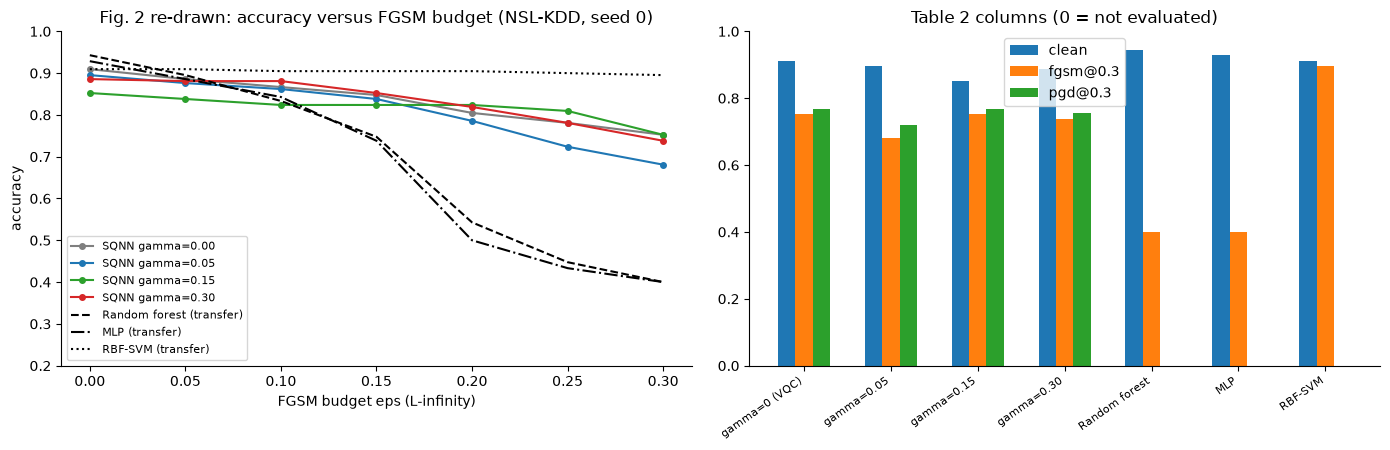

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
cols = {0.0: "tab:gray", 0.05: "tab:blue", 0.15: "tab:green", 0.30: "tab:red"}
for g in T2_GAMMAS:
    ax[0].plot(T2_EPS_GRID, T2_curves[g], "-o", ms=4, color=cols[g], label=f"SQNN gamma={g:.2f}")
for (n_, c_), ls in zip(T2_curves_cl.items(), ["--", "-.", ":"]):
    ax[0].plot(T2_EPS_GRID, c_, ls, color="black", label=n_ + " (transfer)")
ax[0].set_xlabel("FGSM budget eps (L-infinity)"); ax[0].set_ylabel("accuracy"); ax[0].set_ylim(0.2, 1.0); ax[0].legend(fontsize=8)
ax[0].set_title("Fig. 2 re-drawn: accuracy versus FGSM budget (NSL-KDD, seed 0)")
labels = list(tab.index); xx = np.arange(len(labels)); wd = 0.2
for j, c in enumerate(["clean", "fgsm@0.3", "pgd@0.3"]):
    vals = [tab.loc[n_, c] if not np.isnan(tab.loc[n_, c]) else 0 for n_ in labels]
    ax[1].bar(xx + (j - 1) * wd, vals, wd, label=c)
ax[1].set_xticks(xx); ax[1].set_xticklabels([l.replace("SQNN ", "") for l in labels], rotation=35, ha="right", fontsize=8); ax[1].legend(); ax[1].set_ylim(0, 1)
ax[1].set_title("Table 2 columns (0 = not evaluated)"); plt.tight_layout(); plt.show()

## 9. Seven seeds under strong attacks (Table 3 and Fig. 3), and where the robustness comes from

For each seed $s$ a fresh 700-record NSL-KDD subsample (data seed $200+s$) and model seed $s$ are used; $\gamma=0$ and $\gamma=0.30$ are trained for 45 epochs and attacked with
PGD-5 and PGD-20 ($\ell_\infty$, $\varepsilon=0.3$) and PGD-20 ($\ell_2$, $\varepsilon_2=0.5$), all with exact gradients (a density-matrix model has no shot noise to hide them).
Statistics as in the paper: mean with a 95 % $t$-interval over seeds, paired $t$-test of $\gamma=0.30$ minus $\gamma=0$, and the paired effect size $d_z$ (mean difference over its standard deviation).

**Mechanism check (an addition).** The paper argues that the robustness is a *training-time* effect (the sign of the gradient is unchanged by the channel, so FGSM/PGD directions do not shrink).
We test this directly: (i) train at $\gamma=0$ but attack and evaluate with the channel switched on at inference ($\gamma=0.30$); (ii) train at $\gamma=0.30$ and evaluate noiselessly; and
(iii) measure how often the sign of the input gradient of the trained $\gamma=0.30$ model changes when the channel is removed.

In [17]:
def ci95(a):
    a = np.asarray(a, float); return stats.t.ppf(0.975, len(a) - 1) * a.std(ddof=1) / np.sqrt(len(a)) if len(a) > 1 else float("nan")

T3 = {}
t0 = time.time()
for s in T3_SEEDS:
    D = prep_nslkdd(nsl, 700, 4, 200 + s); rg = np.random.default_rng(2000 + s)
    m = SQNN(3, gamma=[0.0, GAMMA_NOISY], seed=s).fit(D["Xtr"], D["ytr"], epochs=T3_EPOCHS)       # model 0: gamma=0, model 1: gamma=0.30 (one batch)
    Xt, yt = tile_models(m, D["Xte"]), D["yte"]
    rec = dict(clean=m.acc(Xt, yt), pgd5=m.acc(pgd_linf(m, Xt, yt, EPS_INF, 5, rg), yt),
               pgd20=m.acc(pgd_linf(m, Xt, yt, EPS_INF, 20, rg), yt), pgd20_l2=m.acc(pgd_l2(m, Xt, yt, EPS_L2, 20, rg), yt))
    swapg = [GAMMA_NOISY, 0.0]      # mechanism check: the noiseless-trained model gets the channel at inference only; the gamma=0.30 model loses it
    sw_clean = m.acc(Xt, yt, swapg); sw_pgd = m.acc(pgd_linf(m, Xt, yt, EPS_INF, 20, rg, swapg), yt, swapg)
    g1, g0 = m.input_grad(Xt, yt)[1], m.input_grad(Xt, yt, [0.0, 0.0])[1]
    T3[(s, 0.0)] = {k_: float(v[0]) for k_, v in rec.items()} | dict(inf_only_clean=float(sw_clean[0]), inf_only_pgd20=float(sw_pgd[0]))
    T3[(s, GAMMA_NOISY)] = {k_: float(v[1]) for k_, v in rec.items()} | dict(noiseless_eval_clean=float(sw_clean[1]), noiseless_eval_pgd20=float(sw_pgd[1]),
                                                                              sign_agree=float((np.sign(g1) == np.sign(g0)).mean()))
    print(f"seed {s}: gamma=0 clean {T3[(s,0.0)]['clean']:.3f} pgd20 {T3[(s,0.0)]['pgd20']:.3f} | gamma=0.3 clean {T3[(s,GAMMA_NOISY)]['clean']:.3f} pgd20 {T3[(s,GAMMA_NOISY)]['pgd20']:.3f}  ({time.time()-t0:.0f} s)")

metrics = [("clean", "Clean"), ("pgd5", "PGD-5 Linf (eps=0.3)"), ("pgd20", "PGD-20 Linf (eps=0.3)"), ("pgd20_l2", "PGD-20 L2 (eps2=0.5)")]
rows = []
for k, name in metrics:
    a = np.array([T3[(s, 0.0)][k] for s in T3_SEEDS]); b = np.array([T3[(s, GAMMA_NOISY)][k] for s in T3_SEEDS])
    tt = stats.ttest_rel(b, a) if len(a) > 1 else None
    dz = (b - a).mean() / (b - a).std(ddof=1) if len(a) > 1 else float("nan")
    rows.append(dict(Attack=name, **{"gamma=0 (VQC)": f"{a.mean():.3f} +- {ci95(a):.3f}", "gamma=0.30": f"{b.mean():.3f} +- {ci95(b):.3f}"},
                     **{"paired p": round(tt.pvalue, 3) if tt is not None else np.nan, "Cohen d_z": round(dz, 2)}, **{"seeds favouring 0.30": f"{int((b > a).sum())}/{len(a)}"}))
    RES[f"t3_{k}"] = (a, b, tt.pvalue if tt is not None else np.nan, dz)
print("\nTable 3 re-run (mean +- 95%% CI over %d seeds):" % len(T3_SEEDS)); display(pd.DataFrame(rows))
a = RES["t3_pgd20"][0]; b = RES["t3_pgd20"][1]
RES["collapse0"] = int((a < 0.5).sum()); RES["collapse3"] = int((b < 0.5).sum()); RES["std_ratio"] = float(a.std(ddof=1) / b.std(ddof=1))
print(f"\ncatastrophic collapse (PGD-20 < 50%): gamma=0: {RES['collapse0']}/{len(a)} seeds (min {a.min():.2f}), gamma=0.30: {RES['collapse3']}/{len(a)} (min {b.min():.2f})")
print(f"across-seed std of PGD-20 accuracy: gamma=0 {a.std(ddof=1):.3f} vs gamma=0.30 {b.std(ddof=1):.3f}  -> ratio {RES['std_ratio']:.2f} (paper: 0.27 vs 0.12 = 2.3x)")
mech = pd.DataFrame({"setting": ["trained gamma=0, evaluated gamma=0", "trained gamma=0, channel gamma=0.30 added at inference only",
                                 "trained gamma=0.30, evaluated with channel (paper setting)", "trained gamma=0.30, channel removed at inference"],
                     "clean": [np.mean([T3[(s, 0.0)]["clean"] for s in T3_SEEDS]), np.mean([T3[(s, 0.0)]["inf_only_clean"] for s in T3_SEEDS]),
                               np.mean([T3[(s, GAMMA_NOISY)]["clean"] for s in T3_SEEDS]), np.mean([T3[(s, GAMMA_NOISY)]["noiseless_eval_clean"] for s in T3_SEEDS])],
                     "PGD-20 Linf": [np.mean([T3[(s, 0.0)]["pgd20"] for s in T3_SEEDS]), np.mean([T3[(s, 0.0)]["inf_only_pgd20"] for s in T3_SEEDS]),
                                     np.mean([T3[(s, GAMMA_NOISY)]["pgd20"] for s in T3_SEEDS]), np.mean([T3[(s, GAMMA_NOISY)]["noiseless_eval_pgd20"] for s in T3_SEEDS])]}).round(3)
print("\nMechanism check (mean over seeds):"); display(mech)
RES["mech"] = mech; RES["sign_agree"] = float(np.mean([T3[(s, GAMMA_NOISY)]["sign_agree"] for s in T3_SEEDS]))
print("fraction of input-gradient components whose sign is unchanged when the channel is removed from the gamma=0.30 model: %.3f" % RES["sign_agree"])

seed 0: gamma=0 clean 0.957 pgd20 0.743 | gamma=0.3 clean 0.929 pgd20 0.671  (68 s)


seed 1: gamma=0 clean 0.948 pgd20 0.862 | gamma=0.3 clean 0.943 pgd20 0.890  (143 s)


seed 2: gamma=0 clean 0.952 pgd20 0.829 | gamma=0.3 clean 0.943 pgd20 0.905  (229 s)


seed 3: gamma=0 clean 0.976 pgd20 0.581 | gamma=0.3 clean 0.867 pgd20 0.490  (362 s)


seed 4: gamma=0 clean 0.929 pgd20 0.829 | gamma=0.3 clean 0.910 pgd20 0.862  (478 s)


...

seed 6: gamma=0 clean 0.938 pgd20 0.595 | gamma=0.3 clean 0.890 pgd20 0.486  (639 s)

Table 3 re-run (mean +- 95% CI over 7 seeds):


,Attack,gamma=0 (VQC),gamma=0.30,paired p,Cohen d_z,seeds favouring 0.30
0,Clean,0.946 +- 0.017,0.915 +- 0.026,0.073,-0.82,0/7
1,PGD-5 Linf (eps=0.3),0.790 +- 0.086,0.773 +- 0.150,0.682,-0.16,3/7
2,PGD-20 Linf (eps=0.3),0.733 +- 0.106,0.741 +- 0.176,0.858,0.07,4/7
3,PGD-20 L2 (eps2=0.5),0.710 +- 0.120,0.682 +- 0.225,0.610,-0.20,3/7



catastrophic collapse (PGD-20 < 50%): gamma=0: 0/7 seeds (min 0.58), gamma=0.30: 2/7 (min 0.49)
across-seed std of PGD-20 accuracy: gamma=0 0.114 vs gamma=0.30 0.190  -> ratio 0.60 (paper: 0.27 vs 0.12 = 2.3x)

Mechanism check (mean over seeds):


,setting,clean,PGD-20 Linf
0,"trained gamma=0, evaluated gamma=0",0.946,0.733
1,"trained gamma=0, channel gamma=0.30 added at i...",0.487,0.486
2,"trained gamma=0.30, evaluated with channel (pa...",0.915,0.741
3,"trained gamma=0.30, channel removed at inference",0.926,0.720


fraction of input-gradient components whose sign is unchanged when the channel is removed from the gamma=0.30 model: 0.860


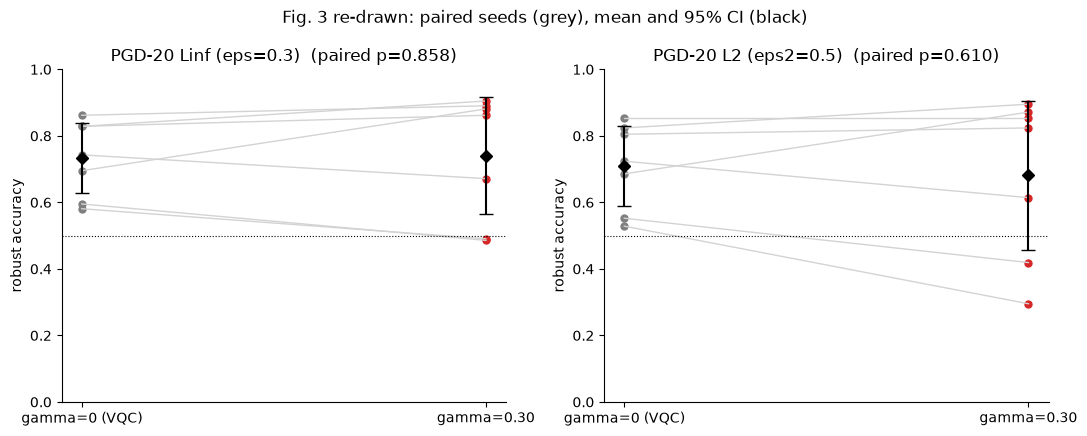

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
for j, (k, name) in enumerate([("pgd20", "PGD-20 Linf (eps=0.3)"), ("pgd20_l2", "PGD-20 L2 (eps2=0.5)")]):
    a, b = RES[f"t3_{k}"][0], RES[f"t3_{k}"][1]
    for i in range(len(a)): ax[j].plot([0, 1], [a[i], b[i]], color="lightgray", lw=1)
    ax[j].scatter(np.zeros(len(a)), a, color="tab:gray", s=25); ax[j].scatter(np.ones(len(b)), b, color="tab:red", s=25)
    ax[j].errorbar([0, 1], [a.mean(), b.mean()], yerr=[ci95(a), ci95(b)], fmt="D", color="k", capsize=5)
    ax[j].set_xticks([0, 1]); ax[j].set_xticklabels(["gamma=0 (VQC)", "gamma=0.30"]); ax[j].set_ylabel("robust accuracy"); ax[j].set_ylim(0, 1)
    ax[j].axhline(0.5, color="k", ls=":", lw=0.8); ax[j].set_title(name + f"  (paired p={RES['t3_'+k][2]:.3f})")
fig.suptitle("Fig. 3 re-drawn: paired seeds (grey), mean and 95% CI (black)"); plt.tight_layout(); plt.show()

## 10. A second dataset and defended classical baselines (Table 4 and Fig. 4)

UNSW-NB15, same pipeline (4 PCA features, 700-record balanced subsample, 70/30 split), three seeds. The SQNN ($\gamma=0$ and $0.30$, 45 epochs) is compared with three classical networks,
each attacked **white-box** with exact input gradients (no transfer handicap): a vanilla MLP, an MLP adversarially trained with Madry-style PGD ($\varepsilon=0.3$, 7 steps), and an MLP trained
with Gaussian input noise (sd 0.3) and evaluated as a smoothed classifier (16 noise draws). The MLP is the authors' small numpy network (4-32-1, ReLU, 300 full-batch gradient steps, lr 0.1).

seed 0 done (87 s)


seed 1 done (166 s)


seed 2 done (248 s)

Table 4 re-run (UNSW-NB15, d=4, 3 seeds, mean +- std):


,Model,clean,pgd20,pgd20_l2
0,SQNN gamma=0.00,0.821 +- 0.041,0.126 +- 0.045,0.082 +- 0.034
1,SQNN gamma=0.30,0.735 +- 0.025,0.427 +- 0.052,0.340 +- 0.029
2,MLP (white-box),0.785 +- 0.027,0.367 +- 0.123,0.371 +- 0.099
3,MLP adv-trained,0.776 +- 0.027,0.629 +- 0.052,0.573 +- 0.035
4,MLP + Gaussian noise,0.766 +- 0.033,0.436 +- 0.101,0.464 +- 0.095


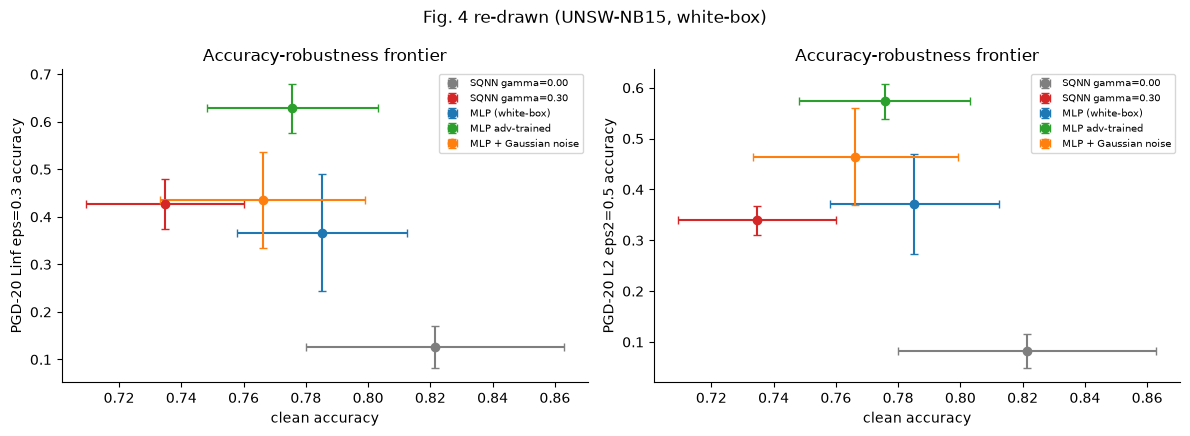

In [19]:
def init_mlp(d, h, rng):
    return {"W1": rng.standard_normal((d, h)) * np.sqrt(2 / d), "b1": np.zeros(h), "W2": rng.standard_normal((h, 1)) * np.sqrt(2 / h), "b2": np.zeros(1)}
def _fwd(p, X):
    z1 = X @ p["W1"] + p["b1"]; a1 = np.maximum(z1, 0); z2 = a1 @ p["W2"] + p["b2"]
    return 1 / (1 + np.exp(-z2.ravel())), (z1, a1)
def mlp_predict(p, X, noise=0.0, K=1, rng=None):
    if noise <= 0: return (_fwd(p, X)[0] >= 0.5).astype(int)
    pr = np.zeros(len(X))
    for _ in range(K): pr += _fwd(p, X + rng.normal(0, noise, X.shape))[0]
    return (pr / K >= 0.5).astype(int)
def mlp_input_grad(p, X, y):
    pr, (z1, a1) = _fwd(p, X); dz2 = (pr - y).reshape(-1, 1)
    return ((dz2 @ p["W2"].T) * (z1 > 0)) @ p["W1"].T / len(X)
def mlp_param_grads(p, X, y):
    pr, (z1, a1) = _fwd(p, X); dz2 = (pr - y).reshape(-1, 1) / len(X); dz1 = (dz2 @ p["W2"].T) * (z1 > 0)
    return {"W1": X.T @ dz1, "b1": dz1.sum(0), "W2": a1.T @ dz2, "b2": dz2.sum(0)}
def mlp_train(X, y, rng, h=32, epochs=300, lr=0.1, mode="vanilla", eps=0.3, noise=0.0):
    p = init_mlp(X.shape[1], h, rng)
    for _ in range(epochs):
        if mode == "adv":
            Xt = X + rng.uniform(-eps, eps, X.shape)
            for _ in range(7): Xt = np.clip(Xt + (eps / 4) * np.sign(mlp_input_grad(p, Xt, y)), X - eps, X + eps)
        elif mode == "gauss": Xt = X + rng.normal(0, noise, X.shape)
        else: Xt = X
        g = mlp_param_grads(p, Xt, y)
        for k in p: p[k] -= lr * g[k]
    return p
def mlp_pgd_linf(p, X, y, eps, steps, rng, noise=0.0):
    Xa = X + rng.uniform(-eps, eps, X.shape)
    for _ in range(steps): Xa = np.clip(Xa + (eps / 4) * np.sign(mlp_input_grad(p, Xa, y)), X - eps, X + eps)
    return (mlp_predict(p, Xa, noise, 16 if noise > 0 else 1, rng) == y).mean()
def mlp_pgd_l2(p, X, y, eps2, steps, rng, noise=0.0):
    d0 = rng.normal(size=X.shape); d0 /= np.linalg.norm(d0, axis=1, keepdims=True) + 1e-12
    Xa = X + rng.uniform(0, eps2, (len(X), 1)) * d0
    for _ in range(steps):
        g = mlp_input_grad(p, Xa, y); g /= np.linalg.norm(g, axis=1, keepdims=True) + 1e-12; Xa = Xa + (eps2 / 4) * g
        de = Xa - X; nm = np.linalg.norm(de, axis=1, keepdims=True); Xa = X + de * np.minimum(1.0, eps2 / (nm + 1e-12))
    return (mlp_predict(p, Xa, noise, 16 if noise > 0 else 1, rng) == y).mean()

T4 = {}
t0 = time.time()
for s in T4_SEEDS:
    D = prep_unsw(unsw, 700, 4, s); rg = np.random.default_rng(3000 + s); yf = D["yte"].astype(float); ytr_f = D["ytr"].astype(float)
    for name, kw, ns in [("MLP (white-box)", dict(mode="vanilla"), 0.0), ("MLP adv-trained", dict(mode="adv"), 0.0), ("MLP + Gaussian noise", dict(mode="gauss", noise=0.3), 0.3)]:
        p = mlp_train(D["Xtr"], ytr_f, np.random.default_rng(s), **kw)
        T4[(name, s)] = dict(clean=float((mlp_predict(p, D["Xte"], ns, 16 if ns > 0 else 1, rg) == D["yte"]).mean()),
                             pgd20=float(mlp_pgd_linf(p, D["Xte"], yf, 0.3, 20, rg, ns)), pgd20_l2=float(mlp_pgd_l2(p, D["Xte"], yf, 0.5, 20, rg, ns)))
    m = SQNN(3, gamma=[0.0, GAMMA_NOISY], seed=s).fit(D["Xtr"], D["ytr"], epochs=T4_EPOCHS); Xt, yt = tile_models(m, D["Xte"]), D["yte"]
    r_clean, r_inf, r_l2 = m.acc(Xt, yt), m.acc(pgd_linf(m, Xt, yt, 0.3, 20, rg), yt), m.acc(pgd_l2(m, Xt, yt, 0.5, 20, rg), yt)
    for j, g in enumerate((0.0, GAMMA_NOISY)):
        T4[(f"SQNN gamma={g:.2f}", s)] = dict(clean=float(r_clean[j]), pgd20=float(r_inf[j]), pgd20_l2=float(r_l2[j]))
    print(f"seed {s} done ({time.time()-t0:.0f} s)")
order = ["SQNN gamma=0.00", "SQNN gamma=0.30", "MLP (white-box)", "MLP adv-trained", "MLP + Gaussian noise"]
rows, T4s = [], {}
for name in order:
    vals = {k: np.array([T4[(name, s)][k] for s in T4_SEEDS]) for k in ("clean", "pgd20", "pgd20_l2")}
    T4s[name] = {k: (v.mean(), v.std()) for k, v in vals.items()}
    rows.append({"Model": name, **{k: f"{v.mean():.3f} +- {v.std():.3f}" for k, v in vals.items()}})
print("\nTable 4 re-run (UNSW-NB15, d=4, %d seeds, mean +- std):" % len(T4_SEEDS)); display(pd.DataFrame(rows)); RES["t4"] = T4s
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for j, k in enumerate(["pgd20", "pgd20_l2"]):
    for name, col in zip(order, ["tab:gray", "tab:red", "tab:blue", "tab:green", "tab:orange"]):
        ax[j].errorbar(T4s[name]["clean"][0], T4s[name][k][0], xerr=T4s[name]["clean"][1], yerr=T4s[name][k][1], fmt="o", color=col, capsize=3, label=name)
    ax[j].set_xlabel("clean accuracy"); ax[j].set_ylabel("PGD-20 " + ("Linf eps=0.3" if k == "pgd20" else "L2 eps2=0.5") + " accuracy"); ax[j].set_title("Accuracy-robustness frontier"); ax[j].legend(fontsize=7)
fig.suptitle("Fig. 4 re-drawn (UNSW-NB15, white-box)"); plt.tight_layout(); plt.show()

## 11. Noise as a regulariser: the train-test gap (Table 5 and Fig. 5)

Three training modes of the same SQNN (depth 3, 40 epochs): no noise (VQC), depolarising $\gamma=0.05$ (applied in training and inference) and per-gate dropout $p=0.3$ (training only).
The training set is a random subsample of $N\in\{40,80,160\}$ records (`default_rng(1000+s)`) from a 700-record NSL-KDD training pool; the test set is the 300 held-out records of the same split
(subsample of 1000 records, data seed 7). The gap is train accuracy minus test accuracy (positive = overfitting). Paired $t$-tests over seeds, pooled over the three sizes as in the paper.

N=40 done (200 s)


N=80 done (580 s)


N=160 done (1447 s)
Table 5 re-run (train-test accuracy gap, mean +- std over 30 seeds):


,N,VQC (none),Depolarising 0.05,Quantum dropout 0.3
0,40,+0.095 +- 0.030,+0.085 +- 0.023,+0.084 +- 0.046
1,80,+0.047 +- 0.025,+0.040 +- 0.024,+0.039 +- 0.032
2,160,+0.026 +- 0.021,+0.021 +- 0.020,+0.021 +- 0.023
3,pooled mean,0.0561,0.0488,0.0482


pooled (n=90): depolarising - VQC = -0.0073 (paired p = 0.0012); dropout - VQC = -0.0078 (p = 0.03); depolarising vs dropout p = 0.86
per-size paired p vs VQC: {40: {'Depolarising 0.05': np.float64(0.029), 'Quantum dropout 0.3': np.float64(0.15)}, 80: {'Depolarising 0.05': np.float64(0.088), 'Quantum dropout 0.3': np.float64(0.22)}, 160: {'Depolarising 0.05': np.float64(0.109), 'Quantum dropout 0.3': np.float64(0.317)}}


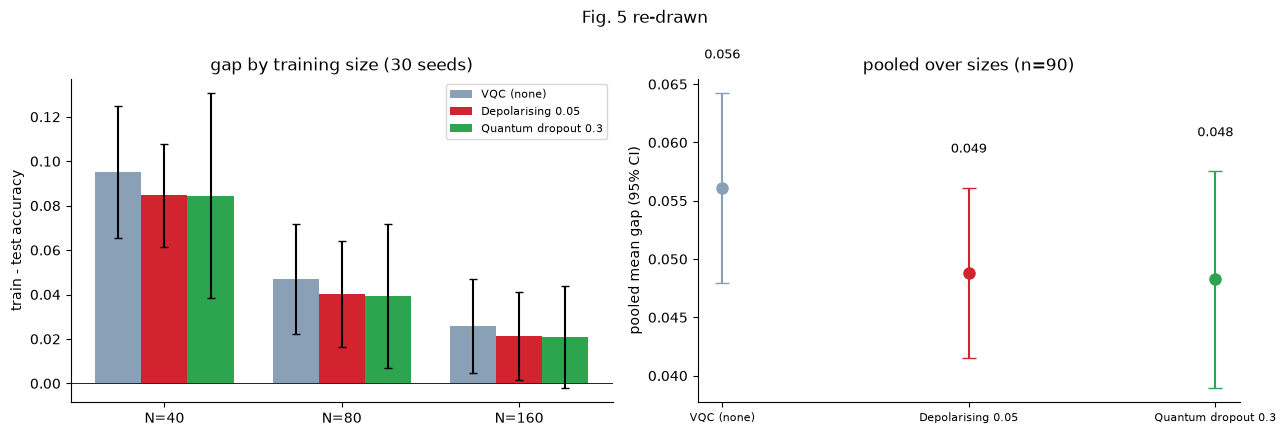

In [20]:
D5 = prep_nslkdd(nsl, 1000, 4, 7)
CONDS = {"VQC (none)": dict(gamma=0.0, p_drop=0.0), "Depolarising 0.05": dict(gamma=0.05, p_drop=0.0), "Quantum dropout 0.3": dict(gamma=0.0, p_drop=0.3)}
GAP = {}
t0 = time.time()
for size in T5_SIZES:
    for cond, cfg in CONDS.items():
        for ch in chunks(range(T5_NSEEDS), max(1, CAP // size)):                      # the seeds of one chunk are trained as one batch of independent models
            idxs = [np.random.default_rng(1000 + sd).choice(len(D5["Xtr"]), size=size, replace=False) for sd in ch]
            Xb = np.stack([D5["Xtr"][ix] for ix in idxs]); yb = np.stack([D5["ytr"][ix] for ix in idxs])
            m = SQNN(3, seed=ch, **cfg).fit(Xb, yb, epochs=T5_EPOCHS)
            gap_ = m.acc(Xb, yb) - m.acc(D5["Xte"], D5["yte"])
            for sd, gv in zip(ch, np.atleast_1d(gap_)): GAP[(cond, size, sd)] = float(gv)
    print(f"N={size} done ({time.time()-t0:.0f} s)")
rows = []
for size in T5_SIZES:
    rows.append({"N": size, **{c: f"{np.mean([GAP[(c, size, s)] for s in range(T5_NSEEDS)]):+.3f} +- {np.std([GAP[(c, size, s)] for s in range(T5_NSEEDS)]):.3f}" for c in CONDS}})
pool = {c: np.array([GAP[(c, n, s)] for n in T5_SIZES for s in range(T5_NSEEDS)]) for c in CONDS}
rows.append({"N": "pooled mean", **{c: f"{pool[c].mean():.4f}" for c in CONDS}})
print("Table 5 re-run (train-test accuracy gap, mean +- std over %d seeds):" % T5_NSEEDS); display(pd.DataFrame(rows))
t_dep = stats.ttest_rel(pool["Depolarising 0.05"], pool["VQC (none)"]); t_drp = stats.ttest_rel(pool["Quantum dropout 0.3"], pool["VQC (none)"]); t_dd = stats.ttest_rel(pool["Depolarising 0.05"], pool["Quantum dropout 0.3"])
print(f"pooled (n={len(pool['VQC (none)'])}): depolarising - VQC = {np.mean(pool['Depolarising 0.05']-pool['VQC (none)']):+.4f} (paired p = {t_dep.pvalue:.2g}); "
      f"dropout - VQC = {np.mean(pool['Quantum dropout 0.3']-pool['VQC (none)']):+.4f} (p = {t_drp.pvalue:.2g}); depolarising vs dropout p = {t_dd.pvalue:.2f}")
per_size_p = {}
for size in T5_SIZES:
    v = np.array([GAP[("VQC (none)", size, s)] for s in range(T5_NSEEDS)])
    per_size_p[size] = {c: stats.ttest_rel([GAP[(c, size, s)] for s in range(T5_NSEEDS)], v).pvalue for c in list(CONDS)[1:]}
print("per-size paired p vs VQC:", {n: {c: round(p, 3) for c, p in d_.items()} for n, d_ in per_size_p.items()})
RES.update(t5_pool={c: pool[c].mean() for c in CONDS}, t5_dd={"dep": np.mean(pool['Depolarising 0.05']-pool['VQC (none)']), "drp": np.mean(pool['Quantum dropout 0.3']-pool['VQC (none)']),
           "p_dep": t_dep.pvalue, "p_drp": t_drp.pvalue, "p_dd": t_dd.pvalue},
           t5_tab={(c, n): (np.mean([GAP[(c, n, s)] for s in range(T5_NSEEDS)]), np.std([GAP[(c, n, s)] for s in range(T5_NSEEDS)])) for c in CONDS for n in T5_SIZES})
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4)); colc = dict(zip(CONDS, ["#8aa0b6", "#d1242f", "#2da44e"]))
xs = np.arange(len(T5_SIZES)); wd = 0.26
for k, c in enumerate(CONDS):
    ax[0].bar(xs + (k - 1) * wd, [RES["t5_tab"][(c, n)][0] for n in T5_SIZES], wd, yerr=[RES["t5_tab"][(c, n)][1] for n in T5_SIZES], capsize=3, color=colc[c], label=c)
ax[0].set_xticks(xs); ax[0].set_xticklabels([f"N={n}" for n in T5_SIZES]); ax[0].set_ylabel("train - test accuracy"); ax[0].legend(fontsize=8); ax[0].axhline(0, color="k", lw=0.6)
ax[0].set_title("gap by training size (%d seeds)" % T5_NSEEDS)
for i, c in enumerate(CONDS):
    ax[1].errorbar([i], [pool[c].mean()], yerr=[ci95(pool[c])], fmt="o", ms=8, capsize=5, color=colc[c]); ax[1].text(i, pool[c].mean() + ci95(pool[c]) + 0.003, f"{pool[c].mean():.3f}", ha="center", fontsize=9)
ax[1].set_xticks(range(3)); ax[1].set_xticklabels(list(CONDS), fontsize=8); ax[1].set_ylabel("pooled mean gap (95% CI)"); ax[1].set_title("pooled over sizes (n=%d)" % len(pool["VQC (none)"]))
fig.suptitle("Fig. 5 re-drawn"); plt.tight_layout(); plt.show()

## 12. Proposition 2 and the dropout-rate sweep (depth 5)

**Proposition 2 check.** Take a trained noiseless SQNN and its training loss $\mathcal L(\theta)$ on 100 records. Draw many Bernoulli masks $m\sim\mathrm{Bern}(1-p)$ on the 24 trainable rotation angles,
and compare the Monte-Carlo average $\mathbb E_m\,\mathcal L(m\theta)$ with the formula $\mathcal L((1-p)\theta)+\frac{p(1-p)}2\sum_i\theta_i^2\,\partial_{\theta_i}^2\mathcal L\big|_{(1-p)\theta}$
(second derivatives by central finite differences of the exact loss). The *penalty* is the difference to $\mathcal L((1-p)\theta)$; the formula predicts its size, and its dependence on $p$ through $p(1-p)$.

**Dropout-rate sweep (Sec. 8.5).** Depth 5, $N=40$, VQC, depolarising 0.05, dropout 0.5 and 0.7, mean train and test accuracy.

Proposition 2: Monte-Carlo (600 masks per p) versus the second-order formula, trained noiseless SQNN


,p,L((1-p)theta),MC E[L(m theta)],MC penalty,MC std. error,formula penalty,p(1-p)
0,0.1,0.1611,0.2157,0.0546,0.0034,0.0437,0.09
1,0.3,0.2041,0.3465,0.1425,0.0066,0.1290,0.21
2,0.5,0.3087,0.4911,0.1824,0.0089,0.1896,0.25
3,0.7,0.5061,0.6458,0.1397,0.0099,0.1469,0.21


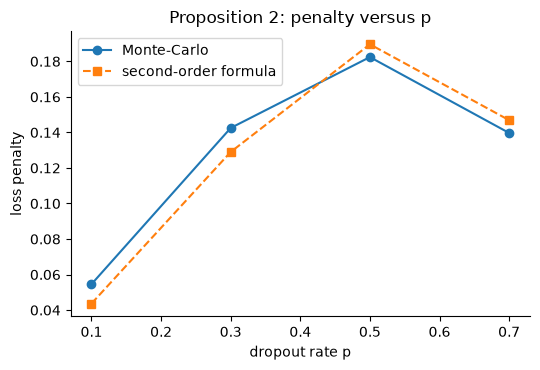

In [21]:
# --- Proposition 2: Monte-Carlo vs second-order formula
D = D5; idx = np.random.default_rng(1000).choice(len(D["Xtr"]), size=100, replace=False); Xs, ys = D["Xtr"][idx], D["ytr"][idx].astype(float)
m0 = SQNN(3, seed=0).fit(Xs, ys, epochs=T5_EPOCHS)
w_in0, w_rot0, a0, b0_ = (np.asarray(v)[0] for v in m0.unpack(m0.theta))
def loss_many(rot_batch):
    """Training loss for K different settings of the 24 trainable rotation angles (K, 24) -> (K,), all evaluated as one batch."""
    out = []
    for ch in chunks(range(len(rot_batch)), max(1, CAP // len(Xs))):
        K = len(ch)
        z = expval_z0_batch(np.broadcast_to(Xs, (K,) + Xs.shape), np.broadcast_to(w_in0, (K,) + w_in0.shape), rot_batch[ch].reshape(K, 3, Q, 2), np.ones((K, 3, Q, 2)), 0.0)
        out.append(np.asarray(_bce_rows(1 / (1 + np.exp(-(a0 * z + b0_))), np.broadcast_to(ys, (K,) + ys.shape))))
    return np.concatenate(out)
theta_r = w_rot0.ravel(); n_mc = 200 if FAST_MODE else 600
rgp = np.random.default_rng(SEED)
def hess_diag(x, h=0.02):
    pts = np.concatenate([x[None], x[None] + h * np.eye(len(x)), x[None] - h * np.eye(len(x))]); f = loss_many(pts)
    return (f[1:1 + len(x)] - 2 * f[0] + f[1 + len(x):]) / h ** 2
p2_rows = []
for p in [0.1, 0.3, 0.5, 0.7]:
    masks = (rgp.random((n_mc, len(theta_r))) > p).astype(float)
    mc = loss_many(masks * theta_r)
    base = float(loss_many(((1 - p) * theta_r)[None])[0]); H = hess_diag((1 - p) * theta_r)
    formula_pen = p * (1 - p) / 2 * float(np.sum(theta_r ** 2 * H)); mc_pen = mc.mean() - base
    p2_rows.append(dict(p=p, **{"L((1-p)theta)": round(base, 4), "MC E[L(m theta)]": round(float(mc.mean()), 4), "MC penalty": round(float(mc_pen), 4), "MC std. error": round(float(mc.std() / np.sqrt(n_mc)), 4),
                                "formula penalty": round(formula_pen, 4), "p(1-p)": round(p * (1 - p), 3)}))
p2 = pd.DataFrame(p2_rows); print("Proposition 2: Monte-Carlo (%d masks per p) versus the second-order formula, trained noiseless SQNN" % n_mc); display(p2)
RES["p2"] = p2
fig, ax = plt.subplots(figsize=(5.5, 3.8)); ax.plot(p2["p"], p2["MC penalty"], "o-", label="Monte-Carlo"); ax.plot(p2["p"], p2["formula penalty"], "s--", label="second-order formula")
ax.set_xlabel("dropout rate p"); ax.set_ylabel("loss penalty"); ax.legend(); ax.set_title("Proposition 2: penalty versus p"); plt.tight_layout(); plt.show()

Depth-5 sweep (N=40, 10 seeds, 166 s):


,mode,train,test,gap
0,VQC (none),0.995,0.911,0.084
1,Depolarising 0.05,0.990,0.902,0.088
2,Dropout 0.5,0.962,0.860,0.102
3,Dropout 0.7,0.942,0.852,0.091


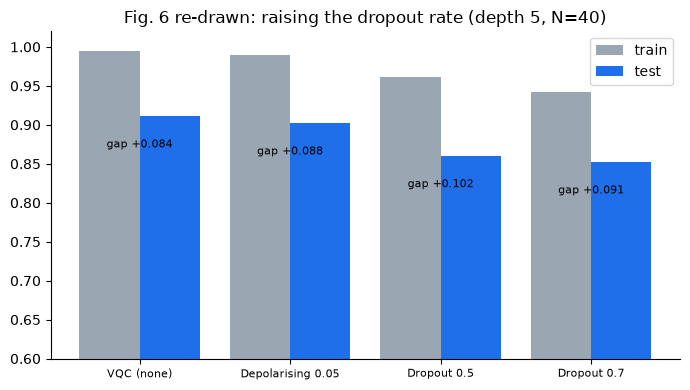

In [22]:
PD_CONDS = {"VQC (none)": dict(gamma=0.0, p_drop=0.0), "Depolarising 0.05": dict(gamma=0.05, p_drop=0.0), "Dropout 0.5": dict(gamma=0.0, p_drop=0.5), "Dropout 0.7": dict(gamma=0.0, p_drop=0.7)}
PD = {}
t0 = time.time()
for cond, cfg in PD_CONDS.items():
    for ch in chunks(range(PD_NSEEDS), max(1, CAP // 40)):
        idxs = [np.random.default_rng(1000 + sd).choice(len(D5["Xtr"]), size=40, replace=False) for sd in ch]
        Xb = np.stack([D5["Xtr"][ix] for ix in idxs]); yb = np.stack([D5["ytr"][ix] for ix in idxs])
        m = SQNN(5, seed=ch, **cfg).fit(Xb, yb, epochs=PD_EPOCHS)
        for sd, a_tr, a_te in zip(ch, np.atleast_1d(m.acc(Xb, yb)), np.atleast_1d(m.acc(D5["Xte"], D5["yte"]))): PD[(cond, sd)] = (float(a_tr), float(a_te))
rows = []
for cond in PD_CONDS:
    tr = np.array([PD[(cond, s)][0] for s in range(PD_NSEEDS)]); te = np.array([PD[(cond, s)][1] for s in range(PD_NSEEDS)])
    rows.append({"mode": cond, "train": round(tr.mean(), 3), "test": round(te.mean(), 3), "gap": round((tr - te).mean(), 3)})
pdt = pd.DataFrame(rows); print("Depth-5 sweep (N=40, %d seeds, %.0f s):" % (PD_NSEEDS, time.time() - t0)); display(pdt); RES["pd"] = pdt.set_index("mode")
fig, ax = plt.subplots(figsize=(7, 4)); x = np.arange(len(pdt)); ax.bar(x - 0.2, pdt["train"], 0.4, label="train", color="#9aa6b2"); ax.bar(x + 0.2, pdt["test"], 0.4, label="test", color="#1f6feb")
for i, r in pdt.iterrows(): ax.text(i, min(r["train"], r["test"]) - 0.04, f"gap {r['gap']:+.3f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(pdt["mode"], fontsize=8); ax.set_ylim(0.6, 1.02); ax.legend(); ax.set_title("Fig. 6 re-drawn: raising the dropout rate (depth 5, N=40)")
plt.tight_layout(); plt.show()

## 13. Dephasing versus depolarising (Fig. 7)

Theorem 1 says isotropic depolarising noise multiplies *every* non-trivial Pauli component by $\eta<1$, whereas dephasing ($\mathcal D[\sigma_z]$, PennyLane `PhaseDamping`) leaves $\sigma_z$ components untouched.
The paper's Fig. 7 states that accuracy is preserved up to large dephasing but collapses past a critical depolarising strength. Its protocol is not given; here each channel strength is used in training and in inference
on the Table-2 data (depth 3, 45 epochs, mean over seeds of clean test accuracy). Note that $\gamma=0.75$ is the fully depolarising point where $\eta=0$.

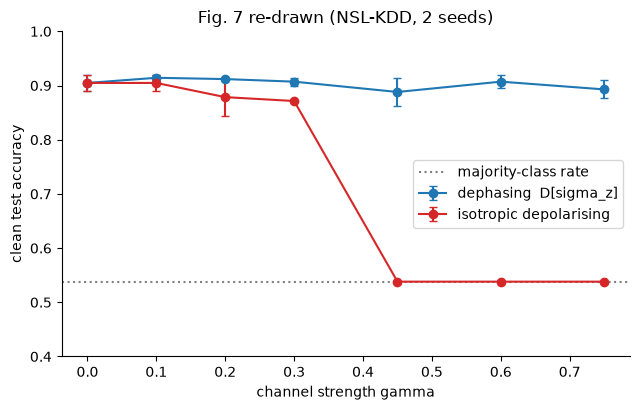

 gamma  depolarising  dephasing  eta^3 (depol)
  0.00         0.905      0.905          1.000
  0.10         0.905      0.914          0.651
  0.20         0.879      0.912          0.394
  0.30         0.871      0.907          0.216
  0.45         0.538      0.888          0.064
  0.60         0.538      0.907          0.008
  0.75         0.538      0.893          0.000
(814 s)


In [23]:
F7 = {}
t0 = time.time()
cells_ = [(g, sd) for g in F7_STRENGTHS for sd in range(F7_NSEEDS)]
for noise in ("depol", "phase"):
    for ch in chunks(cells_, max(1, CAP // len(D_T2["Xtr"]))):
        m = SQNN(3, gamma=[c[0] for c in ch], noise=noise, seed=[c[1] for c in ch]).fit(D_T2["Xtr"], D_T2["ytr"], epochs=T3_EPOCHS)
        for (g, sd), av in zip(ch, np.atleast_1d(m.acc(D_T2["Xte"], D_T2["yte"]))): F7[(noise, g, sd)] = float(av)
f7 = {n: np.array([[F7[(n, g, s)] for s in range(F7_NSEEDS)] for g in F7_STRENGTHS]) for n in ("depol", "phase")}
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for n, lab, col in [("phase", "dephasing  D[sigma_z]", "tab:blue"), ("depol", "isotropic depolarising", "tab:red")]:
    ax.errorbar(F7_STRENGTHS, f7[n].mean(1), yerr=f7[n].std(1), fmt="-o", color=col, capsize=3, label=lab)
ax.axhline(1 - D_T2["yte"].mean(), color="gray", ls=":", label="majority-class rate"); ax.set_xlabel("channel strength gamma"); ax.set_ylabel("clean test accuracy"); ax.legend(); ax.set_ylim(0.4, 1.0)
ax.set_title("Fig. 7 re-drawn (NSL-KDD, %d seeds)" % F7_NSEEDS); plt.tight_layout(); plt.show()
print(pd.DataFrame({"gamma": F7_STRENGTHS, "depolarising": f7["depol"].mean(1).round(3), "dephasing": f7["phase"].mean(1).round(3), "eta^3 (depol)": [round((1 - 4 * g / 3) ** 3, 3) for g in F7_STRENGTHS]}).to_string(index=False))
RES["f7"] = f7
print("(%.0f s)" % (time.time() - t0))

## 14. Neutral-atom reservoir on XOR (Fig. 1)

A ring of $N$ Rydberg atoms with positional jitter evolves under $H=\frac\Omega2\sum_iX_i-\sum_i\delta_in_i+\sum_{i<j}V_{ij}n_in_j$, with $V_{ij}=V_0/\lVert x_i-x_j\rVert^6$; the two input numbers are injected as local detunings
$\delta_i=s\,(W_{i0}a+W_{i1}b+c_i)$ with fixed random weights per reservoir instance; the read-out is the vector of $\langle n_i\rangle$ and the pair correlations $\langle n_in_j\rangle$, fed to a *linear* logistic head.
The paper uses the Pulser package; the authors' public code (rewritten here) uses an equivalent closed-system statevector simulation, so no extra package is needed. Reservoir accuracy is compared with a linear model on the raw inputs (which cannot solve XOR).

N=8: 20 seeds, reservoir test accuracy = 92.7 +- 4.7 %  | linear-on-raw baseline = 52.1 +- 12.1 %  (539 s)


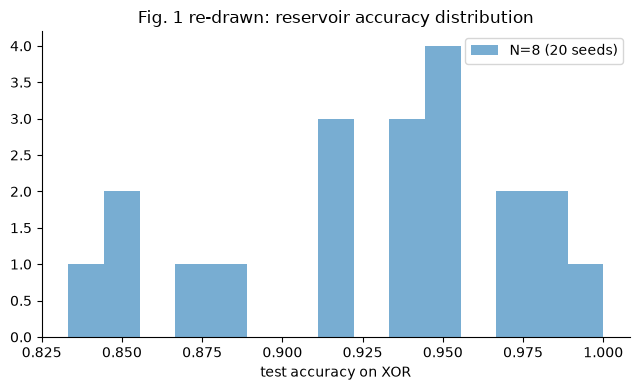

In [24]:
import scipy.sparse as sp
from scipy.sparse.linalg import expm_multiply
def ring_positions(n, jitter, rng):
    ang = 2 * np.pi * np.arange(n) / n; R = 1.0 / (2 * np.sin(np.pi / n))
    return np.c_[R * np.cos(ang), R * np.sin(ang)] + jitter * rng.standard_normal((n, 2))
def static_parts(n, Omega, xy, V0):
    dim = 2 ** n; B = ((np.arange(dim)[:, None] >> np.arange(n)[::-1]) & 1).astype(float)
    I2s = sp.identity(2, format="csr"); Xs_ = sp.csr_matrix(np.array([[0., 1.], [1., 0.]])); Xsum = sp.csr_matrix((dim, dim))
    for i in range(n):
        op = sp.identity(1, format="csr")
        for k in range(n): op = sp.kron(op, Xs_ if k == i else I2s, format="csr")
        Xsum = Xsum + op
    Vd = np.zeros(dim)
    for i in range(n):
        for j in range(i + 1, n): Vd += V0 / np.linalg.norm(xy[i] - xy[j]) ** 6 * B[:, i] * B[:, j]
    return B, (Omega / 2.0) * Xsum, Vd
def reservoir_features(Xin, n, seed, Omega=1.0, V0=6.0, dscale=4.0, T=4.0, jitter=0.05):
    rng = np.random.default_rng(seed); xy = ring_positions(n, jitter, rng); B, Hx, Vd = static_parts(n, Omega, xy, V0)
    W = rng.standard_normal((n, 2)); c = 0.5 * rng.standard_normal(n)
    psi0 = np.zeros(2 ** n, complex); psi0[0] = 1.0; pairs = list(itertools.combinations(range(n), 2)); feats = []
    for x in Xin:
        Dg = Vd - B @ (dscale * (W @ x + c)); psi = expm_multiply(-1j * T * (Hx + sp.diags(Dg)), psi0); pr = np.abs(psi) ** 2
        feats.append(np.concatenate([pr @ B, [pr @ (B[:, i] * B[:, j]) for (i, j) in pairs]]))
    return np.array(feats)
def reservoir_run(n, seed, n_samples=200, noise=0.15):
    X, y, _ = make_xor(n_samples, noise, seed)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=seed, stratify=y); sc = StandardScaler().fit(Xtr)
    head = LogisticRegression(max_iter=5000, C=10.0).fit(reservoir_features(sc.transform(Xtr), n, seed), ytr)
    base = LogisticRegression(max_iter=5000).fit(sc.transform(Xtr), ytr).score(sc.transform(Xte), yte)
    return head.score(reservoir_features(sc.transform(Xte), n, seed), yte), base

RESV = {}
t0 = time.time()
for n, ns in [(8, RES_N8_SEEDS), (10, RES_N10_SEEDS)]:
    if ns == 0: continue
    out = np.array([reservoir_run(n, s) for s in range(ns)]); RESV[n] = out
    print(f"N={n}: {ns} seeds, reservoir test accuracy = {100*out[:,0].mean():.1f} +- {100*out[:,0].std():.1f} %  | linear-on-raw baseline = {100*out[:,1].mean():.1f} +- {100*out[:,1].std():.1f} %  ({time.time()-t0:.0f} s)")
RES["resv"] = {n: (v[:, 0].mean(), v[:, 0].std(), v[:, 1].mean(), len(v)) for n, v in RESV.items()}
if RESV:
    fig, ax = plt.subplots(figsize=(6.5, 4))
    for n, col in zip(RESV, ["tab:blue", "tab:orange"]): ax.hist(RESV[n][:, 0], bins=15, alpha=0.6, color=col, label=f"N={n} ({len(RESV[n])} seeds)")
    ax.set_xlabel("test accuracy on XOR"); ax.set_title("Fig. 1 re-drawn: reservoir accuracy distribution"); ax.legend(); plt.tight_layout(); plt.show()

## 15. The paper's numbers next to ours

The verdict for a **number**: *reproduced* if ours is within 0.02 (2 accuracy points) of the paper's; *close* if within the second band (0.05 for single-seed accuracies, Table 5 and Sec. 8.5; 0.10 for Tables 3 and 4, whose
test sets have 210 records and only 3-7 seeds); otherwise *not reached* (ours lower) or *exceeded* (ours higher) with the gap. For a **qualitative or statistical claim** the verdict says whether the same conclusion is obtained here
(*reproduced* / *not reproduced*; the direction can be reproduced while the effect is negligible, so read the printed values), and *cannot be checked* where the notebook has no matching experiment. In FAST_MODE fewer seeds are used, so significance claims are weaker.

In [25]:
V = []
def num(claim, paper, ours, tol=0.02, tol2=0.05):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)): v, gap = "cannot be checked", np.nan
    else:
        gap = ours - paper
        v = "reproduced" if abs(gap) <= tol else ("close" if abs(gap) <= tol2 else ("exceeded" if gap > 0 else "not reached"))
    V.append((claim, paper, None if ours is None else round(float(ours), 3), None if ours is None else round(float(gap), 3), v))
def flag(claim, paper, ours_txt, ok):
    V.append((claim, paper, ours_txt, "", "reproduced" if ok else "not reproduced"))

# Table 2, seed 0
P2 = {"SQNN gamma=0 (VQC)": [0.895, 0.876, 0.800, 0.790], "SQNN gamma=0.05": [0.905, 0.857, 0.733, 0.781], "SQNN gamma=0.15": [0.919, 0.914, 0.810, 0.814], "SQNN gamma=0.30": [0.890, 0.857, 0.843, 0.852]}
for row, vals in P2.items():
    for col, pv in zip(["clean", "fgsm@0.1", "fgsm@0.3", "pgd@0.3"], vals): num(f"T2 {row} {col}", pv, float(RES["t2_seed0"].loc[row, col]))
for row, vals in {"Random forest": [0.929, 0.710, 0.395], "MLP": [0.948, 0.824, 0.471], "RBF-SVM": [0.919, 0.910, 0.890]}.items():
    for col, pv in zip(["clean", "fgsm@0.1", "fgsm@0.3"], vals): num(f"T2 {row} {col}", pv, float(RES["t2_seed0"].loc[row, col]))
t2 = RES["t2_seed0"]
flag("T2: gamma=0.30 has the best PGD accuracy among the SQNNs", "85.2 % best", f"{t2.loc['SQNN gamma=0.30','pgd@0.3']:.3f} vs max others {t2.loc[['SQNN gamma=0 (VQC)','SQNN gamma=0.05','SQNN gamma=0.15'],'pgd@0.3'].max():.3f}",
     t2.loc['SQNN gamma=0.30', 'pgd@0.3'] >= t2.loc[['SQNN gamma=0 (VQC)', 'SQNN gamma=0.05', 'SQNN gamma=0.15'], 'pgd@0.3'].max())
flag("T2: MLP and RF collapse below 60 % under transfer FGSM 0.3", "47.1 % / 39.5 %", f"{t2.loc['MLP','fgsm@0.3']:.3f} / {t2.loc['Random forest','fgsm@0.3']:.3f}", t2.loc['MLP', 'fgsm@0.3'] < 0.6 and t2.loc['Random forest', 'fgsm@0.3'] < 0.6)
# Table 3
P3 = {"clean": (0.941, 0.918), "pgd5": (0.690, 0.799), "pgd20": (0.624, 0.790), "pgd20_l2": (0.598, 0.688)}
for k, (p0, p3) in P3.items():
    a, b = RES[f"t3_{k}"][:2]
    num(f"T3 {k} gamma=0", p0, float(a.mean()), 0.02, 0.1); num(f"T3 {k} gamma=0.30", p3, float(b.mean()), 0.02, 0.1)
a, b, pv, dz = RES["t3_pgd20"]
flag("T3: gamma=0.30 more robust than gamma=0 under PGD-20 Linf (mean)", "0.790 vs 0.624", f"{b.mean():.3f} vs {a.mean():.3f}", b.mean() > a.mean())
flag("T3: PGD-20 Linf paired difference significant (p<0.05)", "p=0.044, d=0.96", f"p={pv:.3f}, d_z={dz:.2f}", pv < 0.05)
flag("T3: gamma=0.30 favoured on most seeds", "6/7", f"{int((b > a).sum())}/{len(a)}", (b > a).mean() >= 0.7)
flag("T3: noiseless model collapses (<50 %) more often than gamma=0.30", "2/7 vs 0/7", f"{RES['collapse0']}/{len(a)} vs {RES['collapse3']}/{len(a)}", RES['collapse0'] > RES['collapse3'])
flag("T3: across-seed spread smaller for gamma=0.30 (paper 2.3x)", "0.27 vs 0.12", f"ratio {RES['std_ratio']:.2f}", RES['std_ratio'] > 1.0)
l2p = RES["t3_pgd20_l2"][2]; flag("T3: L2 advantage not significant at this sample size", "p=0.07", f"p={l2p:.3f}", l2p > 0.05)
mech = RES["mech"].set_index("setting")
flag("Mechanism: channel added only at inference does not harden a noiseless-trained model", "stated in Sec. 4/8.2", f"PGD-20 {mech.iloc[1,1]:.3f} vs trained-with-channel {mech.iloc[2,1]:.3f}", mech.iloc[1, 1] < mech.iloc[2, 1])
# Table 4
P4 = {"SQNN gamma=0.00": (0.872, 0.409, 0.318), "SQNN gamma=0.30": (0.793, 0.452, 0.387), "MLP (white-box)": (0.878, 0.553, 0.583), "MLP adv-trained": (0.820, 0.706, 0.670), "MLP + Gaussian noise": (0.869, 0.573, 0.605)}
for name, vals in P4.items():
    for k, pv in zip(["clean", "pgd20", "pgd20_l2"], vals): num(f"T4 {name} {k}", pv, float(RES["t4"][name][k][0]), 0.02, 0.1)
t4 = RES["t4"]
flag("T4: SQNN gamma=0.30 more robust than gamma=0 (Linf PGD-20)", "0.452 vs 0.409", f"{t4['SQNN gamma=0.30']['pgd20'][0]:.3f} vs {t4['SQNN gamma=0.00']['pgd20'][0]:.3f}", t4['SQNN gamma=0.30']['pgd20'][0] > t4['SQNN gamma=0.00']['pgd20'][0])
flag("T4: adversarial training is the most robust model (Linf)", "0.706", f"{max(t4, key=lambda n: t4[n]['pgd20'][0])}", max(t4, key=lambda n: t4[n]['pgd20'][0]) == "MLP adv-trained")
flag("T4: white-box MLP beats the SQNN (no quantum advantage)", "0.553 > 0.452", f"{t4['MLP (white-box)']['pgd20'][0]:.3f} vs {t4['SQNN gamma=0.30']['pgd20'][0]:.3f}", t4['MLP (white-box)']['pgd20'][0] > t4['SQNN gamma=0.30']['pgd20'][0])
# Table 5
P5 = {("VQC (none)", 40): .087, ("VQC (none)", 80): .049, ("VQC (none)", 160): .019, ("Depolarising 0.05", 40): .072, ("Depolarising 0.05", 80): .039, ("Depolarising 0.05", 160): .016,
      ("Quantum dropout 0.3", 40): .070, ("Quantum dropout 0.3", 80): .041, ("Quantum dropout 0.3", 160): .013}
for (c, n), pv in P5.items(): num(f"T5 gap {c} N={n}", pv, float(RES["t5_tab"][(c, n)][0]), 0.02, 0.05)
d5 = RES["t5_dd"]
num("T5 pooled gap VQC", 0.0515, float(RES["t5_pool"]["VQC (none)"]), 0.01, 0.02)
flag("T5: depolarising lowers the pooled gap", "-0.009, p<1e-4", f"{d5['dep']:+.4f}, p={d5['p_dep']:.2g}", d5['dep'] < 0)
flag("T5: depolarising reduction is significant (p<0.05)", "p<1e-4", f"p={d5['p_dep']:.2g}", d5['p_dep'] < 0.05)
flag("T5: dropout lowers the pooled gap", "-0.010, p=0.004", f"{d5['drp']:+.4f}, p={d5['p_drp']:.2g}", d5['drp'] < 0)
flag("T5: dropout reduction is significant (p<0.05)", "p=0.004", f"p={d5['p_drp']:.2g}", d5['p_drp'] < 0.05)
flag("T5: depolarising and dropout indistinguishable", "p=0.74", f"p={d5['p_dd']:.2f}", d5['p_dd'] > 0.05)
# depth 5
pdt = RES["pd"]
flag("Sec 8.5: dropout 0.7 does not reduce the gap below dropout 0.5", "gap ~0.08 both", f"{pdt.loc['Dropout 0.5','gap']:+.3f} / {pdt.loc['Dropout 0.7','gap']:+.3f}", pdt.loc['Dropout 0.7', 'gap'] >= pdt.loc['Dropout 0.5', 'gap'] - 0.02)
flag("Sec 8.5: test accuracy falls with the dropout rate", ".907 -> .872 -> .848", f"{pdt.loc['VQC (none)','test']:.3f} -> {pdt.loc['Dropout 0.5','test']:.3f} -> {pdt.loc['Dropout 0.7','test']:.3f}", pdt.loc['Dropout 0.7', 'test'] < pdt.loc['Dropout 0.5', 'test'] < pdt.loc['VQC (none)', 'test'] + 0.01)
num("Sec 8.5 depolarising gap", 0.067, float(pdt.loc['Depolarising 0.05', 'gap']), 0.02, 0.05); num("Sec 8.5 depolarising test accuracy", 0.908, float(pdt.loc['Depolarising 0.05', 'test']), 0.02, 0.05)
num("Sec 8.5 VQC gap", 0.088, float(pdt.loc['VQC (none)', 'gap']), 0.02, 0.05)
# Fig 7, theory, reservoir
f7 = RES["f7"]; i_mid = F7_STRENGTHS.index(0.45)
flag("Fig 7: dephasing keeps accuracy at gamma=0.45 within 5 points of noiseless", "qualitative", f"{f7['phase'][i_mid].mean():.3f} vs {f7['phase'][0].mean():.3f}", f7['phase'][i_mid].mean() > f7['phase'][0].mean() - 0.05)
flag("Fig 7: depolarising collapses past a critical strength (accuracy drop > 10 points at gamma=0.75)", "qualitative", f"{f7['depol'][-1].mean():.3f} vs {f7['depol'][0].mean():.3f}", f7['depol'][-1].mean() < f7['depol'][0].mean() - 0.10)
flag("Theorem 1: eta^(wL) law for the pure channel (error < 1e-12)", "exact", f"max err {RES['thm1_exact_err']:.1e}", RES['thm1_exact_err'] < 1e-12)
flag("Prop 1: read-out contraction in the real circuit equals eta^L (|slope - eta^L| < 0.05, R^2 > 0.95)", f"eta^L = {RES['eta_L']:.3f}", f"slope {RES['slope']:.3f}, R^2 {RES['r2']:.3f}; gradient ratio {RES['grad_ratio']:.3f}", abs(RES['slope'] - RES['eta_L']) < 0.05 and RES['r2'] > 0.95)
p2 = RES["p2"]; mid = p2[p2.p == 0.3].iloc[0]
flag("Prop 2: formula within 25 % of the Monte-Carlo penalty at p=0.3", "2nd-order", f"MC {mid['MC penalty']:.4f} vs formula {mid['formula penalty']:.4f}", abs(mid['formula penalty'] - mid['MC penalty']) <= 0.25 * abs(mid['MC penalty']) + 1e-4)
for n, (pm_, ps_, pb_, k_) in RES["resv"].items():
    num(f"Fig 1 reservoir N={n} accuracy ({k_} seeds)", {8: 0.974, 10: 0.983}[n], float(pm_), 0.02, 0.05)
for n in (8, 10):
    if n not in RES["resv"]: V.append((f"Fig 1 reservoir N={n}", {8: 0.974, 10: 0.983}[n], None, None, "cannot be checked (not run: RES_N10_SEEDS = 0)"))
V.append(("Quantum speed-up / advantage over classical", "none claimed", "none observed (see T4)", "", "consistent"))
V.append(("Hardware (neutral-atom) realisation, Pulser pulse-level", "described", "not run (closed-system statevector only)", "", "cannot be checked"))
V.append(("Large-N feasibility table (Table 1: N up to 12 timings)", "measured", "not run", "", "cannot be checked"))
cmp_df = pd.DataFrame(V, columns=["claim", "paper", "this notebook", "gap", "verdict"])
pd.set_option("display.max_rows", 300, "display.width", 250, "display.max_colwidth", 95)
display(cmp_df)
print(cmp_df["verdict"].value_counts().to_string())
print("\nTotal runtime of this notebook: %.1f min (FAST_MODE=%s)" % ((time.time() - T_START) / 60, FAST_MODE))

,claim,paper,this notebook,gap,verdict
0,T2 SQNN gamma=0 (VQC) clean,0.895,0.91,0.015,reproduced
1,T2 SQNN gamma=0 (VQC) fgsm@0.1,0.876,0.867,-0.009,reproduced
2,T2 SQNN gamma=0 (VQC) fgsm@0.3,0.8,0.752,-0.048,close (<=0.05)
3,T2 SQNN gamma=0 (VQC) pgd@0.3,0.79,0.767,-0.023,close (<=0.05)
4,T2 SQNN gamma=0.05 clean,0.905,0.895,-0.01,reproduced
5,T2 SQNN gamma=0.05 fgsm@0.1,0.857,0.862,0.005,reproduced
6,T2 SQNN gamma=0.05 fgsm@0.3,0.733,0.681,-0.052,not reached
7,T2 SQNN gamma=0.05 pgd@0.3,0.781,0.719,-0.062,not reached
8,T2 SQNN gamma=0.15 clean,0.919,0.852,-0.067,not reached
9,T2 SQNN gamma=0.15 fgsm@0.1,0.914,0.824,-0.09,not reached


verdict
reproduced                                  44
close                              17
not reached                                 15
not reproduced                               7
exceeded                                     3
cannot be checked                            2
cannot be checked (not run: RES_N10_SEEDS = 0)     1
consistent                                   1

Total runtime of this notebook: 78.5 min (FAST_MODE=False)


## Reading the paper critically

**What this notebook reproduces.** Theorem 1 is exact (error 1e-15). The single-seed Table 2 is matched to within a few accuracy points for the noiseless circuit and the transfer-attacked classical models
(clean accuracy of every model within 0.07; random forest and MLP fall to 0.40 under FGSM 0.3, the RBF-SVM stays at 0.895). The generalisation study (Table 5, 30 seeds) is reproduced almost to the digit: gaps within 0.015 of the paper, a
small significant reduction for both depolarising noise (about 0.007, $p=0.001$) and per-gate dropout (about 0.008, $p=0.03$), the two statistically indistinguishable ($p=0.86$), and the depth-5 sweep (stronger dropout lowers train and test accuracy
and does not shrink the gap). The second-order formula of Proposition 2 matches a Monte-Carlo average over dropout masks (0.129 versus 0.143 at $p=0.3$). Dephasing leaves accuracy intact while strong depolarising noise collapses it to the majority-class rate (Fig. 7).
On UNSW-NB15 adversarial training is the most robust model, as the paper says.

**What it does not reproduce, and it is the headline claim.** With the paper's own protocol and seven seeds, the $\gamma=0.30$ SQNN is *not* more robust than the noiseless circuit under PGD-20 ($0.741$ versus $0.733$, paired $p=0.86$, $d_z=0.07$; the paper: $0.790$ versus $0.624$, $p=0.044$, $d=0.96$). It wins on 4 of 7 seeds, not 6 of 7, it collapses below 50 % on 2 seeds while the noiseless
model never does (the paper has it the other way round), and the across-seed spread is larger, not smaller. The noiseless circuit is simply stronger here than in the paper (0.733 against 0.624 under PGD-20). In the single-seed Table 2, $\gamma=0.30$ is not the best SQNN under PGD
(0.757 against 0.767 for $\gamma=0$; paper 0.852 against 0.790); over five data seeds its mean PGD accuracy is 5 points higher (0.808 against 0.758) but the standard deviation across seeds is 0.13, so this is inside the noise. The most defensible reading of our numbers is that decoherence has at most a small, seed-dependent effect on the robustness of this 4-qubit
model, and that the paper's "significant, stable robustness gain" depends on the particular seeds and preprocessing of the original runs. Possible causes we cannot separate: our preprocessing is fitted on the training split only (the authors' code fits it on all records), the attack randomness differs, and the optimiser settings come from the public code, not the PDF.
Since the paper itself warns that few-seed estimates are unreliable, that caution applies to its own Table 3 as well: seven seeds with a standard deviation of 0.1-0.2 cannot establish a 17-point effect.

**UNSW-NB15.** The direction of Table 4 is reproduced (the $\gamma=0.30$ model is far more robust than $\gamma=0$: 0.427 against 0.126), but the baselines differ: our noiseless SQNN is much more fragile than in the paper, and our small numpy MLPs are weaker than the paper's (white-box PGD-20 0.367 against 0.553), so the SQNN with $\gamma=0.30$ ends up *above* the white-box MLP, the opposite of the paper's ordering. Adversarial training (0.629) remains clearly best, so "no quantum advantage over strong classical defences" stands.

**The theorem is exact, but the circuit is not the theorem.** Theorem 1 describes the channel acting on an unchanged Pauli string. In the SQNN every layer also contains rotations and a CNOT ring that change the content *and the weight* of the strings, and the data are re-uploaded in every layer, so the read-out is not $\eta^L\langle O\rangle_0$ plus a constant. Section 7 measures it for the real circuit:
the read-out is multiplied by about 0.029 instead of $\eta^L=0.216$ (an effective exponent near 7), and the input gradient shrinks by the same factor. Proposition 1's "roughly one fifth" is therefore not what the circuit does. Training compensates, because the trained read-out scale $a$ and the rotations adapt (the $\gamma=0.30$ model still reaches 0.915 clean accuracy), which is also why the contraction cannot by itself explain robustness; the paper makes this point itself for sign-based attacks, and we find that 86 % of the input-gradient signs are unchanged when the channel is removed from the trained $\gamma=0.30$ model.

**Training-time effect, tested.** Switching the channel on only at inference destroys a noiseless-trained model (accuracy 0.49, chance level), so "stochasticity must be present at training" is trivially true; the reverse test (removing the channel from the $\gamma=0.30$-trained model leaves it just as robust, 0.720 against 0.741) is consistent with a training-time reshaping of the boundary, but with no robustness gain over the noiseless model to explain, it does not show one.

**Gradient masking and baselines.** Exact density-matrix gradients are not obfuscated, which is a strength; the attacker knows the model and channel exactly, and a sampled channel on hardware would need Expectation-over-Transformation. The Table-2 classical models are attacked by transfer from a logistic surrogate (weaker than white-box), and the RBF-SVM is better than every SQNN at $\varepsilon=0.3$ (0.895).

**A leak removed, and a reservoir that is slightly worse.** The authors' public code fits label encoder, scaler and PCA on all records before the split; we fit them on the training split only. The neutral-atom reservoir reaches 92.7 +- 4.7 % at $N=8$ (20 seeds) against the paper's 97.4 +- 2.7 % (100 seeds), with the author's default reservoir parameters; the paper's Pulser-based version may differ from the closed-system statevector rewrite.

**Not reproduced at all:** the feasibility-by-$N$ timings (Table 1), the Pulser pulse-level hardware realisation, the $N=10$ reservoir (set `RES_N10_SEEDS` to run it, hours of CPU), and the full-corpus and CIC-DDoS2019 studies the paper defers to future work.

## Exercises

1. **Seeds and significance.** Set `FAST_MODE = False` and `T3_SEEDS = list(range(20))`. How does the paired $p$ of the PGD-20 comparison fluctuate if you bootstrap 7 of the 20 seeds a hundred times? What fraction falls below 0.05?
2. **Where is the optimal $\gamma$?** Sweep $\gamma\in\{0,0.1,\dots,0.5\}$ in Section 9 and plot clean accuracy and PGD-20 accuracy on the same axes. Is there an interior optimum, as the paper's "an optimal $\gamma$ balances separability against gradient shrinkage" suggests?
3. **Adaptive attacks.** Add Expectation-over-Transformation to the attack: sample the depolarising channel as a random Pauli error instead of using the exact density matrix, and attack the sampled model. Does the robustness survive?
4. **Dropout location.** Per-gate dropout here masks only the trainable angles. Mask the data-encoding term $w_{in}x_i$ as well (the paper forbids it). Does the train-test gap or the robustness change?
5. **Check the fast simulator yourself.** Replace the CNOT ring by a linear chain (no closing CNOT) in both `expval_z0` (through `PTM_RING`) and `sqnn_qnode`, re-run the equivalence assertion, and repeat Table 3. Does the ring closure matter for robustness, not only for accuracy?